# Neurons across environments (bat 11719)

Focused version of `preprocess-data-v0j-share.ipynb`. Adds the Krishna bat-11719 sessions to the joint `Bat_Transformer` fit and compares, per environment (**solo / fs / social / return-to-solo**), the pairwise **(residual) readout-weight cosine similarity** against the pairwise **Pearson correlation of 2-D rate maps**.

The same curated units are shared *within a day* (concat sort -> identical `cluster_id`s across that day's sessions), so each day tracks the same neurons across its environments. We use the two days that carry such a sort:

- **250812** (`solo_morning -> fs -> social_evening -> solo_evening`): same 39 units across all four environments.
- **250814** (`solo_morning`, `fs_s2`): same 61 units across solo and field station.

**250813 is excluded.** `fs` is the field station (same room as Dataset_2). Because units are matched only within a day, every cross-environment comparison below is computed **within a single day** and environments are never compared across days.


In [15]:
# for auto-reloading external modules
%load_ext autoreload
%autoreload 2

import numpy as np
from matplotlib import pyplot as plt
from matplotlib.collections import LineCollection
from mpl_toolkits.mplot3d.art3d import Line3DCollection

%matplotlib inline

from scipy.io import loadmat
import glob
import h5py
from scipy.stats import pearsonr
import torch
from torch import nn
from sklearn.metrics import roc_curve, precision_recall_curve, auc
from sklearn.metrics.pairwise import cosine_similarity
from scipy.stats import binned_statistic, wilcoxon
import pandas as pd
import pickle
import re
from datetime import datetime
import seaborn as sns
import ipympl

import os
import sys
sys.path.append(os.path.expanduser('~/Documents/code/utils'))
from plotting import plot_stars

# sys.path.append('/mnt/scratch09/yongrong/projects/bat-intelligence/src/digitalbat')
sys.path.append(os.path.expanduser('~/Documents/code/digitalbat')) 
from digitalbat.datasets.data import bat_data_loader
from digitalbat.models.former import Bat_Transformer
from digitalbat.models.glm import Bat_GLM
from digitalbat.models.layers import ELU1, TransformerEncoderRoPE
from digitalbat.training.trainer import bat_former_trainer
from digitalbat.utility.utils import auprc_per_unit, corr, interpolate_signal_with_nans, lowpass_filter, \
                                    corr, poisson_fraction_deviance_explained, poisson_fde_population, generate_2d_rate_map
from digitalbat.utility.utils import set_random_state, plot_2d_rate_map, plot_2d_trajectory_response, plot_2d_trajectory_response_multiple, \
                                    plot_3d_trajectory, resample_response, nearest_neighbor_score, OrthogonalityPermutationTest
from digitalbat.datasets.data import Data_Prep_for_Raw, bat_data_loader
from digitalbat.utility.interpreter import Saliency, PermutationImportance, ActivationMaximization, ShapAnalysis, Gradient_Bat_Transformer # IntegGradi
from digitalbat.utility.TrajectoryRF import Generate_Synthetic_Trajecories, Time_Resolved_TRF, Time_Resolved_Phase, Trajectory_Level_TRF

from digitalbat.utility.utils import (
        bat_palette, parse_bat, wilcoxon_safe, stars_for_p,
        add_significance_bracket, annotate_pvalue_corner,
    )

BAT_PALETTE = bat_palette()

sys.path.append(os.path.expanduser('~/Documents/code/digitalbat/notebooks'))
from notebook_helpers import (
    DATASET_TARGETS, DIST_THRESH, REW_LOCS, PERCH_LOCS,
    loc_bin_width_rm, N_BINS_PF,
    get_target_locs, compute_target_proximity,
)


def _attach_session_meta(df, session_col='session'):
    """Add `bat` and `date` columns parsed from session names like
    `Dataset_3_14543_240419` (bat = '14543', date = 2024-04-19)."""
    sess = df[session_col]
    df = df.copy()
    df['bat'] = sess.str.split('_').str[2]
    df['date'] = sess.str[-6:].apply(lambda s: datetime.strptime(s, '%y%m%d').date())
    return df

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
seed = 1
set_random_state(seed)

device = 'cuda'

# Toggle synthetic-train comparison.  When True, the training/eval cells
# below run twice (real + synthetic Poisson-resampled spikes from a smoothed
# 3D rate map) and the real-vs-synthetic comparison cells fire.  Set False
# to skip all synthetic work.
RUN_SYNTHETIC = False

# Toggle trajectory-specific synthetic baseline: per-flight-cluster rate
# maps (clusters with > SYNTHETIC_TRAJ_MIN_CLUSTER_SIZE training flights
# get their own rate map; all others are pooled into one).  Independent
# of RUN_SYNTHETIC -- either or both may be enabled.
RUN_SYNTHETIC_TRAJ = False
SYNTHETIC_TRAJ_MIN_CLUSTER_SIZE = 3


In [ ]:
import re

# Shared Mantel / partial-Mantel + MRM (Freedman-Lane + commonality partition)
# helpers now live in notebook_helpers.py.  Imported here with the underscore
# names the analysis cells below use.
from notebook_helpers import (
    spearman as _spearman, partial_r as _partial_r,
    mantel as _mantel, partial_mantel as _partial_mantel,
    dir_both as _dir_both, mantel_directed_pred as _mantel_directed_pred,
    partial_mantel_directed as _partial_mantel_directed,
    partial_mantel_dir_control as _partial_mantel_dir_control,
    zrank, ols_r2, ols_tstat, freedman_lane, build_nuisance, run_mrm_session,
)

# The Krishna bat-11719 sessions (now centralised in digitalbat/datasets/defaults).
# Three days carry recordings; the two multi-env days share a within-day concat
# sort (same cluster_ids), so cross-environment comparisons stay strictly WITHIN a
# day.  250813 contributes a single (solo) environment -- it adds a readout head
# but no cross-environment pair.
#   250812 -> solo_morning -> fs -> social_evening -> solo_evening   (4 envs)
#   250813 -> solo_morning                                           (1 env)
#   250814 -> solo_morning, fs_s2                                    (2 envs)
from digitalbat.datasets.defaults import KRISHNA_SESSION_NAMES as KRISHNA_SESSIONS

# Environment label per Krishna session.  On 250812 the recording order is
# solo_morning -> fs (field station, same room as Dataset_2) -> social_evening
# -> solo_evening, so solo_evening is the post-social 'return to solo'.  250814
# has only solo_morning + fs_s2; the same suffix-based labels apply
# ('_fs' -> fs, 'solo_morning' -> solo).
def session_env(session_name):
    if '_fs' in session_name:
        return 'fs'
    if 'social' in session_name:
        return 'social'
    if 'solo_evening' in session_name:
        return 'return to solo'
    if 'solo_morning' in session_name:
        return 'solo'
    return 'lab'  # the non-Krishna default sessions

def session_day(session_name):
    """The YYMMDD day token shared by a day's sessions ('250812', '250814')."""
    return session_name.split('_')[3]

ENV_ORDER = ['solo', 'fs', 'social', 'return to solo']
ENV_PALETTE = dict(zip(ENV_ORDER, sns.color_palette('colorblind', len(ENV_ORDER))))

# Days carrying a within-day shared concat sort (>= 2 environments), in order.
# Cross-environment / matched-neuron analyses loop over these, one day at a time.
# (250813 has a single environment, so it is excluded here.)
_day_envs = {}
for _s in KRISHNA_SESSIONS:
    _day_envs.setdefault(session_day(_s), set()).add(session_env(_s))
CROSS_ENV_DAYS = sorted(d for d, e in _day_envs.items() if len(e) >= 2)

# Krishna session names (Dataset_Krishna_11719_250812_solo_morning) put the
# 6-digit YYMMDD as the 4th token, not the last one, so the default
# `_attach_session_meta` (str[-6:]) breaks.  Override with a robust parser.
_DATE_RE = re.compile(r'_(\d{6})(?:_|$)')

def _attach_session_meta(df, session_col='session'):
    df = df.copy()
    sess = df[session_col].astype(str)
    df['bat'] = sess.str.split('_').str[2]
    def _date(s):
        m = _DATE_RE.search(s) or re.search(r'(\d{6})$', s)
        return datetime.strptime(m.group(1), '%y%m%d').date()
    df['date'] = sess.apply(_date)
    df['env'] = sess.apply(session_env)
    return df

# Keep bat-colored plots from KeyError-ing on the new bat.
if '11719' not in BAT_PALETTE:
    BAT_PALETTE['11719'] = sns.color_palette('tab10', 10)[len(BAT_PALETTE) % 10]

## Dataloader

In [ ]:
from digitalbat.datasets.defaults import ALL_SESSION_NAMES, make_data_config

# Joint fit over the full session list (18 canonical Dataset 1-3 sessions + the 7
# Krishna bat-11719 sessions); shared with preprocess-data-v0j-share.ipynb and
# model_comparison.ipynb via digitalbat/datasets/defaults.ALL_SESSION_NAMES, so the
# transformer checkpoint trained there loads here unchanged.
session_names = ALL_SESSION_NAMES
data_config = make_data_config(session_names=session_names)
dataloaders, behavior_dim, unit_num_dict, meta_info_dict = bat_data_loader(**data_config)

print(f'{len(session_names)} sessions, behavior_dim={behavior_dim}')
print('Krishna unit counts:', {s.replace("Dataset_Krishna_11719_", ""): unit_num_dict[s]
                                for s in KRISHNA_SESSIONS})
dataloaders, behavior_dim, unit_num_dict

In [ ]:
# --- Flight cluster type distribution for the Krishna sessions (all splits + test) ---
# With split_each_trajectory_flag, each dataset item is one flight, so these are
# counts of flights per cluster type.
ks = sorted(KRISHNA_SESSIONS, key=lambda s: (s.split('_')[3], ENV_ORDER.index(session_env(s))))
ncols = 3
nrows = int(np.ceil(len(ks) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3.3, nrows * 2.5), squeeze=False)
for k, s in enumerate(ks):
    ax = axes[k // ncols, k % ncols]
    ft_all = np.concatenate([dataloaders[sp][s].dataset.flight_type_index.detach().cpu().numpy()
                             for sp in ['train', 'valid', 'test']])
    ft_test = dataloaders['test'][s].dataset.flight_type_index.detach().cpu().numpy()
    uv, c = np.unique(ft_all, return_counts=True)
    uvt, ct = np.unique(ft_test, return_counts=True)
    ax.bar(uv, c, color='gray', label='all splits')
    ax.bar(uvt, ct, color='k', label='test')
    ax.set_xlabel('flight cluster type'); ax.set_ylabel('# flights')
    ax.set_title(f'{session_env(s)} {s.split("_")[3]}  (n={len(ft_all)} flights)', fontsize=9)
for k in range(len(ks), nrows * ncols):
    axes[k // ncols, k % ncols].set_visible(False)
axes[0, 0].legend(loc='best', frameon=False, fontsize=8)
fig.suptitle('Flight cluster type distribution (bat 11719)', y=1.02)
plt.tight_layout(); plt.show()


## Transformer model

In [ ]:
from digitalbat.models.former_defaults import make_model_config

model_config = make_model_config(behavior_dim, unit_num_dict, meta_info_dict)
bat_former = Bat_Transformer(**model_config)
print(f'{sum(p.numel() for p in bat_former.parameters()):,} parameters; '
      f'{len(unit_num_dict)} readout heads')


## Training

Fits a fresh joint model (defaults + 6 Krishna sessions) under a new `DATA_TAG`. Skips training if the checkpoint already exists.

In [ ]:
# Trainer hyperparameters; model_config is set in the previous cell.
from digitalbat.models.former_defaults import DEFAULT_LR, DEFAULT_WEIGHT_DECAY

os.makedirs('./out/bat_former', exist_ok=True)
lr_transformer = DEFAULT_LR
weight_decay_transformer = DEFAULT_WEIGHT_DECAY


In [ ]:
from digitalbat.models.former_defaults import make_model_name, make_trainer_config

# Shared data tag with preprocess-data-v0j-share.ipynb / model_comparison.ipynb
# (the full 18 + 7 session split), so this LOADS the transformer trained there
# instead of refitting a separate checkpoint.
DATA_TAG = '_acc50_full_v2'

set_random_state(seed)
bat_former = Bat_Transformer(**model_config)
model_name = make_model_name(
    seed, lr_transformer, weight_decay_transformer,
    out_dir='./out/bat_former', suffix=DATA_TAG)
trainer_config = make_trainer_config(
    model=bat_former, dataloaders=dataloaders, device=device,
    model_name=model_name, lr=lr_transformer, weight_decay=weight_decay_transformer,
)
if os.path.exists(model_name):
    print(f'checkpoint exists ({model_name}) -- will load below.')
else:
    print(f'training {model_name} ...')
    best_acc, _, acc_vals = bat_former_trainer(**trainer_config)
    print(f'best val score: {best_acc:.4f}')

## Evaluation

In [ ]:
def evaluate_model(model, dataloaders, valid_fn, device, flight_filter=None, meta_info_dict=None):
    """
    Evaluate model on test data.
    
    Args:
        model: trained model in eval mode
        dataloaders: dict with 'test' key
        valid_fn: function(y_true, y_pred) -> scores array
        device: torch device
        flight_filter: None (all), 'ood', or 'indomain'
        meta_info_dict: required if flight_filter is not None
    
    Returns:
        dict mapping session_name -> scores array
    """
    results = {}
    model.eval()
    
    for session_name, session_data in dataloaders['test'].items():
        # Get flight type filter if needed
        if flight_filter == 'ood':
            target_types = np.array(meta_info_dict['flight_type_test_ood'][session_name], dtype=int)
            if target_types.size == 0:
                results[session_name] = np.array([])
                continue
        elif flight_filter == 'indomain':
            target_types = np.array(meta_info_dict['flight_type_test_indomain'][session_name], dtype=int)
        else:
            target_types = None
        
        y_val_list, y_pred_list = [], []
        for batch in session_data:
            X_val = batch.behavior.to(device)
            y_val = batch.spike.to(device)
            mask_val = batch.mask.to(device)
            
            # Filter by flight type if needed
            if target_types is not None:
                batch_mask = np.isin(batch.flight_type_index.numpy(), target_types)
                if not batch_mask.any():
                    continue
                X_val = X_val[batch_mask]
                y_val = y_val[batch_mask]
                mask_val = mask_val[batch_mask]
            
            y_pred = model(session_name, X_val, mask_val)
            y_val_list.append(y_val[mask_val == 1.0].detach().cpu().numpy())
            y_pred_list.append(y_pred[mask_val == 1.0].detach().cpu().numpy())
        
        if y_val_list:
            y_val_np = np.vstack(y_val_list)
            y_pred_np = np.vstack(y_pred_list)
            results[session_name] = valid_fn(y_val_np, y_pred_np)
        else:
            results[session_name] = np.array([])
    
    return results

In [ ]:
# Load the trained encoder and evaluate on the (real) test set.
metrics = {
    'corr': lambda y_true, y_pred: corr(y_true, y_pred, axis=0),
    'fde': lambda y_true, y_pred: poisson_fde_population(y_true, y_pred),
}
flight_filters = [None, 'ood', 'indomain']  # None = all flights

bat_former.load_state_dict(torch.load(model_name, map_location=device))
bat_former = bat_former.to(device)
bat_former.eval()

transformer_results = {}
for metric_name, valid_fn in metrics.items():
    for flight_filter in flight_filters:
        key = f"{metric_name}_{flight_filter or 'all'}"
        transformer_results[key] = evaluate_model(
            bat_former, dataloaders, valid_fn, device,
            flight_filter=flight_filter, meta_info_dict=meta_info_dict,
        )
        all_scores = np.hstack([v for v in transformer_results[key].values() if len(v) > 0])
        stat = np.nanmedian if 'fde' in key else np.nanmean
        print(f'{key}: {stat(all_scores):.4f}')

# Krishna-only summary
print('\nKrishna corr_all (mean per session):')
for s in KRISHNA_SESSIONS:
    v = transformer_results['corr_all'][s]
    print(f'  {session_env(s):>15} {s.split("_")[3]}: {np.nanmean(v):.3f}  (n={len(v)})')


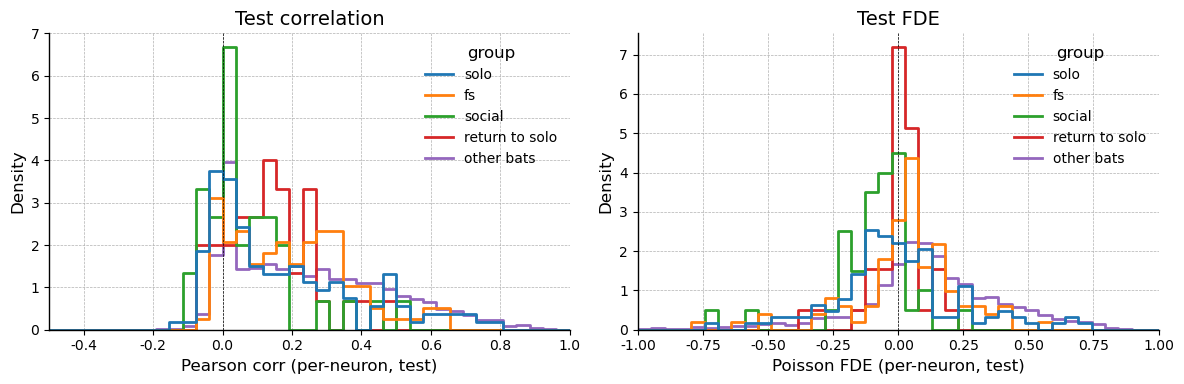

Median per-neuron test scores by group:
                    corr       fde
group                             
solo            0.096897 -0.054925
fs              0.188920  0.041332
social          0.030110 -0.062342
return to solo  0.129194  0.011876
other bats      0.217143  0.081809


In [20]:
# --- Histograms of per-neuron test corr / FDE, by Krishna environment vs other bats ---
rows = []
for s in dataloaders['test'].keys():
    rows.append(pd.DataFrame({
        'corr': np.asarray(transformer_results['corr_all'][s]),
        'fde': np.asarray(transformer_results['fde_all'][s]),
        'session': s,
        'group': session_env(s) if s in KRISHNA_SESSIONS else 'other bats',
    }))
score_df = pd.concat(rows, ignore_index=True)
present = [g for g in (ENV_ORDER + ['other bats']) if g in set(score_df['group'])]

specs = [('corr', 'Pearson corr', np.linspace(-0.5, 1.0, 40)),
         ('fde', 'Poisson FDE', np.linspace(-1.0, 1.0, 40))]  # FDE unbounded below -> bound the AXIS, not the data
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (col, label, bins) in zip(axes, specs):
    sns.histplot(data=score_df, x=col, hue='group', hue_order=present, bins=bins,
                 stat='density', common_norm=False, element='step', fill=False, ax=ax)
    ax.set_xlim(bins[0], bins[-1])
    ax.axvline(0, color='k', lw=0.5, ls='--')
    ax.set_xlabel(f'{label} (per-neuron, test)')
axes[0].set_title('Test correlation')
axes[1].set_title('Test FDE')
plt.tight_layout(); plt.show()

print('Median per-neuron test scores by group:')
print(score_df.groupby('group')[['corr', 'fde']].median().reindex(present).to_string())


## Single-cell rate maps across environments (per day)

For each day with a shared concat sort, two figures (**row = cell, col = environment**) show the same units across that day's environments — **250812** (39 cells × 4 envs: solo → fs → social → return) and **250814** (61 cells × 2 envs: solo, fs). The first figure is the **binned (smoothed) rate map**, the second the **trajectory rate map** (flight-path samples colored by spike count). Each row shares one color scale across that day's environments so a cell's tuning can be compared within the day. These use observed spikes only (independent of the per-neuron table below).


In [21]:
# --- Cache per-timepoint flight position + observed spikes per day, for the
# single-cell rate-map / trajectory figures.  Each day's sessions share one
# concat sort (row i == same unit across that day's environments), so the
# figures compare a cell's tuning across environments WITHIN a day. ---
dt_rm = data_config['bin_width']

day_viz = {}   # day -> dict(sessions, envs, n_cells, flight_xy, flight_spk, flight_lims)
for DAY in CROSS_ENV_DAYS:
    viz_sessions = sorted([s for s in KRISHNA_SESSIONS if f'_{DAY}_' in s],
                          key=lambda s: ENV_ORDER.index(session_env(s)))
    viz_envs = [session_env(s) for s in viz_sessions]

    flight_xy, flight_spk, flight_lims = {}, {}, {}
    for s in viz_sessions:
        Xl, yl, ml = [], [], []
        for b in dataloaders['test'][s]:
            Xl.append(b.behavior.numpy()); yl.append(b.spike.numpy()); ml.append(b.mask.numpy())
        Xa, ya, ma = np.vstack(Xl), np.vstack(yl), np.vstack(ml)
        bm = meta_info_dict['behavior_mean'][s]; bs = meta_info_dict['behavior_std'][s]
        lx = Xa[:, :, 0][ma == 1.0] * bs[0, 0, 0] + bm[0, 0, 0]
        ly = Xa[:, :, 1][ma == 1.0] * bs[0, 0, 1] + bm[0, 0, 1]
        flight_xy[s] = (lx, ly)
        flight_spk[s] = ya[ma == 1.0]                   # (n_valid_timepoints, n_neurons)
        flight_lims[s] = (meta_info_dict['r_lim'][s][0], meta_info_dict['r_lim'][s][1])

    n_cells = flight_spk[viz_sessions[0]].shape[1]
    assert all(flight_spk[s].shape[1] == n_cells for s in viz_sessions), f'{DAY} unit count mismatch'
    day_viz[DAY] = dict(sessions=viz_sessions, envs=viz_envs, n_cells=n_cells,
                        flight_xy=flight_xy, flight_spk=flight_spk, flight_lims=flight_lims)
    print(f'{DAY}: {n_cells} cells x {len(viz_sessions)} environments {viz_envs}; '
          f'valid flight bins per env: {[flight_spk[s].shape[0] for s in viz_sessions]}')


250812: 39 cells x 4 environments ['solo', 'fs', 'social', 'return to solo']; valid flight bins per env: [170, 522, 288, 497]
250814: 61 cells x 2 environments ['solo', 'fs']; valid flight bins per env: [164, 654]


In [ ]:
# --- Figure 1: binned (smoothed) rate maps, row = cell, col = environment ---
# One figure per day.  Observed spikes only.  Each row (cell) shares one color
# scale across that day's environments so brightness is directly comparable;
# peak rate is printed at left.  Each adjacent env pair (col j-1 vs col j) is
# labelled with the within-neuron Pearson correlation of the two rate maps.
# The displayed panels use each env's own spatial extent, but the correlation
# is computed on a COMMON grid (union of the day's env limits) over bins
# SUFFICIENTLY SAMPLED in both environments (>= MIN_OCC_BINS visits, matching
# the preprocess-data-v0j rate-map floor), so a single fly-through can't define
# a bin and shared empty bins do not inflate r.
MIN_OCC_BINS = 3   # min visits per bin to count toward the cross-env correlation
for DAY, dv in day_viz.items():
    viz_sessions, viz_envs, n_cells_viz = dv['sessions'], dv['envs'], dv['n_cells']
    flight_xy, flight_spk, flight_lims = dv['flight_xy'], dv['flight_spk'], dv['flight_lims']

    # Per-session maps for display (each env on its own extent).
    sm_maps = {s: [] for s in viz_sessions}; sm_edges = {}
    for s in viz_sessions:
        lx, ly = flight_xy[s]; spk = flight_spk[s]
        xlim, ylim = flight_lims[s]
        for i in range(n_cells_viz):
            xe, ye, _, sm = generate_2d_rate_map(lx, ly, spk[:, i], xlim, ylim, loc_bin_width_rm, dt_rm)
            sm_maps[s].append(sm)
        sm_edges[s] = (xe, ye)

    # Common-grid maps + occupancy for cross-env within-neuron correlation.
    xl = [flight_lims[s][0] for s in viz_sessions]
    yl = [flight_lims[s][1] for s in viz_sessions]
    xlim_c = (min(x[0] for x in xl), max(x[1] for x in xl))
    ylim_c = (min(y[0] for y in yl), max(y[1] for y in yl))
    xe_c = np.arange(xlim_c[0], xlim_c[1] + loc_bin_width_rm, loc_bin_width_rm)
    ye_c = np.arange(ylim_c[0], ylim_c[1] + loc_bin_width_rm, loc_bin_width_rm)
    cm_maps = {s: [] for s in viz_sessions}; occ_c = {}
    for s in viz_sessions:
        lx, ly = flight_xy[s]; spk = flight_spk[s]
        occ_c[s] = np.histogram2d(lx, ly, bins=[xe_c, ye_c])[0]
        for i in range(n_cells_viz):
            _, _, _, sm = generate_2d_rate_map(lx, ly, spk[:, i], xlim_c, ylim_c, loc_bin_width_rm, dt_rm)
            cm_maps[s].append(sm)

    nrow, ncol = n_cells_viz, len(viz_sessions)
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * 1.7, nrow * 1.15), squeeze=False)
    for i in range(nrow):
        row_vmax = max(np.nanmax(sm_maps[s][i]) for s in viz_sessions)
        row_vmax = row_vmax if row_vmax > 0 else 1.0
        for j, s in enumerate(viz_sessions):
            xe, ye = sm_edges[s]; ax = axes[i, j]
            ax.imshow(sm_maps[s][i].T, origin='lower', vmin=0, vmax=row_vmax,
                      extent=[xe[0], xe[-1], ye[0], ye[-1]], aspect='auto', cmap='hot_r')
            ax.set_xticks([]); ax.set_yticks([])
            if i == 0:
                ax.set_title(viz_envs[j], fontsize=10)
            # Within-neuron Pearson r of this cell's rate map vs the previous env's,
            # over bins occupied in both environments (common grid).
            if j > 0:
                sp = viz_sessions[j - 1]
                a = cm_maps[sp][i]; b = cm_maps[s][i]
                m = (occ_c[sp] >= MIN_OCC_BINS) & (occ_c[s] >= MIN_OCC_BINS)
                av, bv = a[m], b[m]
                r = (np.corrcoef(av, bv)[0, 1]
                     if av.size > 2 and np.std(av) > 0 and np.std(bv) > 0 else np.nan)
                ax.text(0.5, 0.98, f'r={r:.2f}' if np.isfinite(r) else 'r=n/a',
                        transform=ax.transAxes, ha='center', va='top', fontsize=6,
                        bbox=dict(boxstyle='round,pad=0.1', fc='white', ec='none', alpha=0.6))
        pt = meta_info_dict['pType'][viz_sessions[0]][i]   # '' for filtered (empty-array) units
        pt = pt if isinstance(pt, str) else ''
        axes[i, 0].set_ylabel(f'cell {i}\n{row_vmax:.1f} Hz\n{pt}', fontsize=6,
                              rotation=0, ha='right', va='center')
    fig.suptitle(f'Binned rate maps (observed) - bat 11719, day {DAY}  '
                 '(row = cell, col = environment; per-row shared scale; r = within-cell map corr vs prev env)', y=1.002, fontsize=12)
    plt.tight_layout(); plt.show()


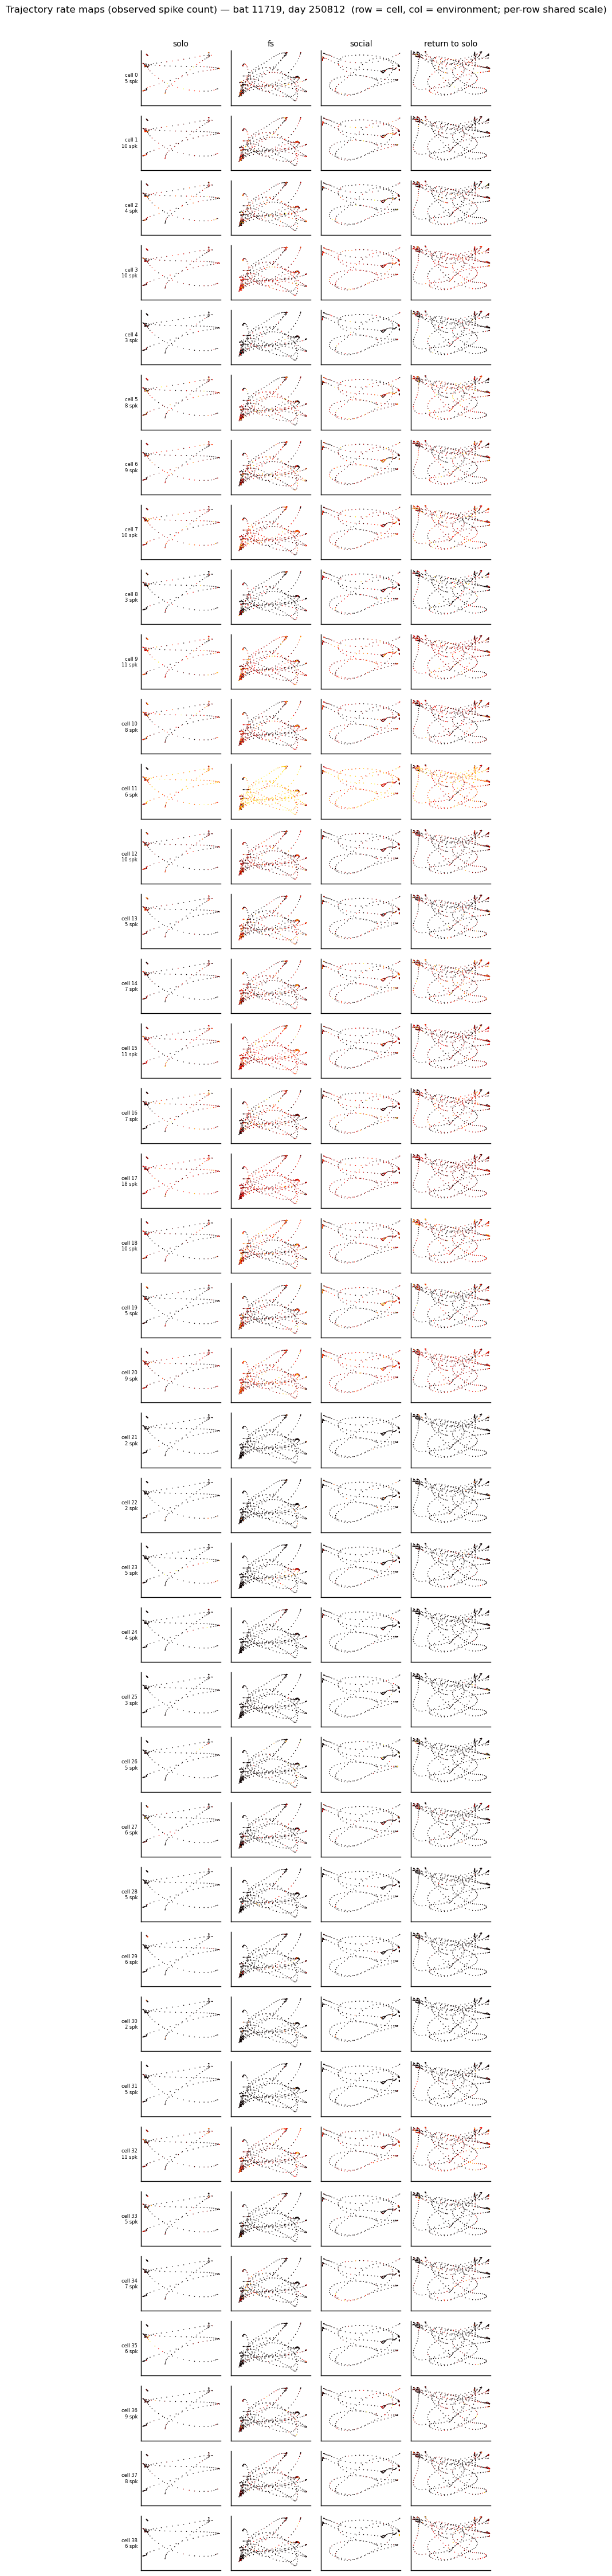

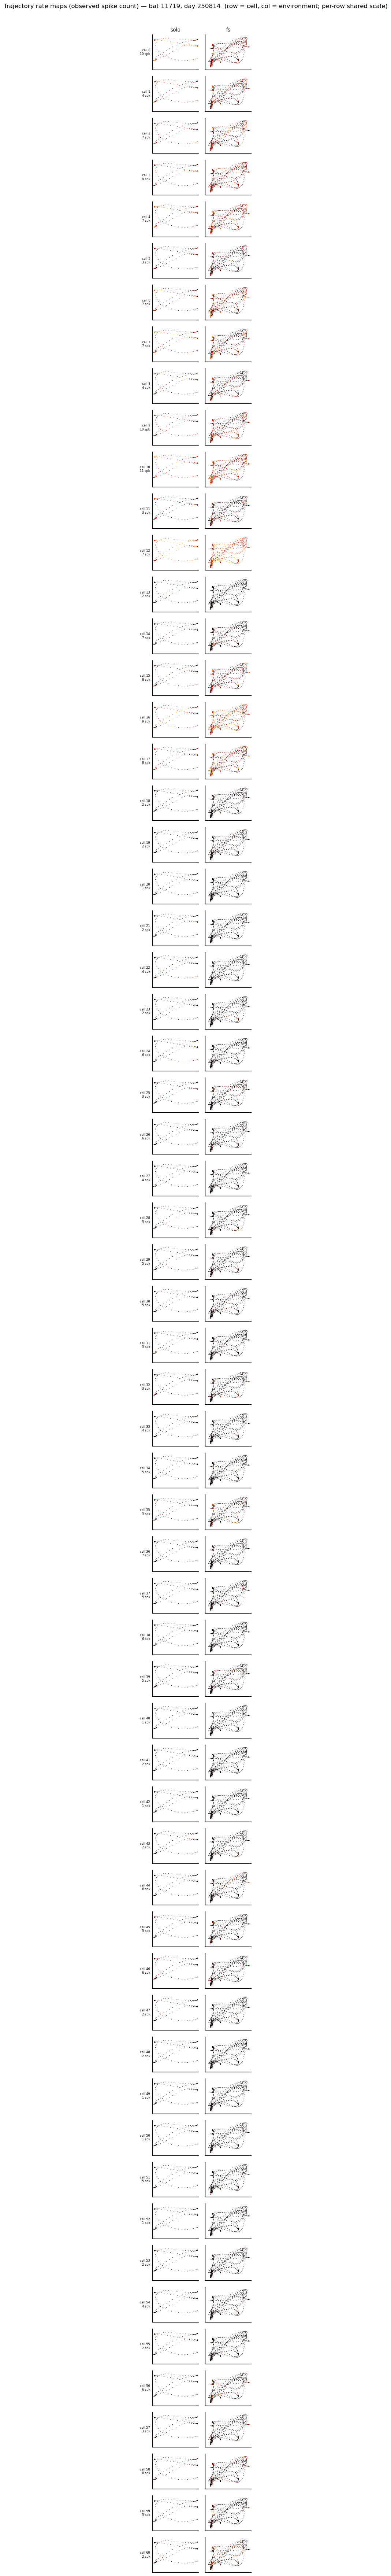

In [23]:
# --- Figure 2: trajectory rate maps, row = cell, col = environment ---
# One figure per day.  Flight-path samples scatter-colored by observed spike
# count (per 0.1 s bin), high counts drawn on top.  Per-row shared color scale
# across that day's environments.
for DAY, dv in day_viz.items():
    viz_sessions, viz_envs, n_cells_viz = dv['sessions'], dv['envs'], dv['n_cells']
    flight_xy, flight_spk, flight_lims = dv['flight_xy'], dv['flight_spk'], dv['flight_lims']

    nrow, ncol = n_cells_viz, len(viz_sessions)
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * 1.7, nrow * 1.15), squeeze=False)
    for i in range(nrow):
        row_vmax = max(int(flight_spk[s][:, i].max()) for s in viz_sessions)
        row_vmax = row_vmax if row_vmax > 0 else 1
        for j, s in enumerate(viz_sessions):
            lx, ly = flight_xy[s]; sc = flight_spk[s][:, i]
            xlim, ylim = flight_lims[s]; order = np.argsort(sc)   # high spike counts on top
            ax = axes[i, j]
            ax.scatter(lx[order], ly[order], c=sc[order], cmap='hot', s=1.2,
                       vmin=0, vmax=row_vmax, linewidths=0)
            ax.set_xlim(xlim); ax.set_ylim(ylim)
            ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect('auto')
            if i == 0:
                ax.set_title(viz_envs[j], fontsize=10)
        axes[i, 0].set_ylabel(f'cell {i}\n{int(row_vmax)} spk', fontsize=6,
                              rotation=0, ha='right', va='center')
    fig.suptitle(f'Trajectory rate maps (observed spike count) — bat 11719, day {DAY}  '
                 '(row = cell, col = environment; per-row shared scale)', y=1.002, fontsize=12)
    plt.tight_layout(); plt.show()


## Per-neuron table (readout weights, pType, mean FR)

In [ ]:
inds_sessions = {} # a dictionary of neuronal indices for each session
pType_sessions = {}  # pType arrays from meta_info_dict, filtered to selected units
readout_weight_sessions = [] # readout weights for selected units from all sessions
for session_target in list(dataloaders['test'].keys()):
    readout_weights = bat_former.readouts[session_target][0].weight.detach().cpu().numpy()
    n_neurons = readout_weights.shape[0]
    inds = np.arange(n_neurons)
    inds_sessions[session_target] = inds
    pType_sessions[session_target] = np.asarray(meta_info_dict['pType'][session_target])
    readout_weight_sessions.append(readout_weights)
readout_weight_sessions = np.vstack(readout_weight_sessions)
print(f'readout_weight_sessions.shape: {readout_weight_sessions.shape}')

inds_sessions_df = pd.concat(
    [
        pd.DataFrame({
            "session_neuron_idx": inds,
            "session_name": session
        })
        for session, inds in inds_sessions.items()
    ],
    ignore_index=True
)
inds_sessions_df["global_neuron_idx"] = range(len(inds_sessions_df))

# Attach pType (putative cell type)
inds_sessions_df['pType'] = np.concatenate(
    [pType_sessions[s] for s in inds_sessions.keys()]
)

# Attach probe identity
inds_sessions_df['probe_id'] = np.concatenate(
    [meta_info_dict['probe_id'][s] for s in inds_sessions.keys()]
)

# Attach neuron position (µm)
positions = np.vstack([meta_info_dict['neuron_position'][s] for s in inds_sessions.keys()])
inds_sessions_df['neuron_pos_lateral'] = positions[:, 0]  # spikePos_um col0 = x
inds_sessions_df['neuron_pos_depth'] = positions[:, 1]    # spikePos_um col1 = y/depth

# Compute mean firing rate per neuron from test data
mean_fr_sessions = {}
for session_name, session_data in dataloaders['test'].items():
    y_list, mask_list = [], []
    for batch in session_data:
        y_list.append(batch.spike.numpy())
        mask_list.append(batch.mask.numpy())
    y_all = np.vstack(y_list)
    mask_all = np.vstack(mask_list)
    spikes_flat = y_all[mask_all == 1.0]
    mean_fr_sessions[session_name] = spikes_flat.mean(axis=0) / data_config['bin_width']
inds_sessions_df['mean_fr'] = np.concatenate(
    [mean_fr_sessions[s] for s in inds_sessions.keys()]
)

# Attach per-neuron metrics from transformer_results. evaluate_model
# returns np.array([]) for sessions with no flights matching the filter
# (e.g., when meta_info_dict['flight_type_test_ood'][session] is empty),
# so pad those with NaNs of length n_neurons to keep length alignment
# with inds_sessions_df.
for key in transformer_results:
    chunks = []
    for s in inds_sessions.keys():
        scores = np.asarray(transformer_results[key][s])
        n = len(inds_sessions[s])
        chunks.append(scores if scores.size == n else np.full(n, np.nan))
    inds_sessions_df[key] = np.concatenate(chunks)

# # Attach per-neuron p-values from circular-shift null
# for key in transformer_pvals:
#     inds_sessions_df[f'p_{key}'] = np.concatenate(
#         [transformer_pvals[key][s] for s in inds_sessions.keys()]
#     )

# Store readout weights (unit-normed) directly in the dataframe
norms = np.linalg.norm(readout_weight_sessions, axis=1, keepdims=True)
readout_normed = readout_weight_sessions / norms
inds_sessions_df['readout_weight'] = list(readout_normed)
inds_sessions_df.loc[inds_sessions_df['pType'].apply(lambda x: isinstance(x, np.ndarray)), 'pType'] = 'filtered'
inds_sessions_df = _attach_session_meta(inds_sessions_df, session_col='session_name')
ct_df = inds_sessions_df[inds_sessions_df['pType'].isin(['pPYR', 'pINT'])].copy()

## Rate maps (observed spikes)

In [ ]:
# Compute 2D rate maps for all neurons in each session
# Uses observed spike counts (not model predictions)
dt_rm = data_config['bin_width']

session_rate_maps = {}  # session -> {'all': array(n_neurons, n_flat_bins), 'top_cluster': ...}
session_top_cluster = {}

for session_name, session_data in dataloaders['test'].items():
    X_list, y_list, mask_list, ftype_list = [], [], [], []
    for batch in session_data:
        X_list.append(batch.behavior.numpy())
        y_list.append(batch.spike.numpy())
        mask_list.append(batch.mask.numpy())
        ftype_list.append(batch.flight_type_index.numpy())

    X_all = np.vstack(X_list)
    y_all = np.vstack(y_list)
    mask_all = np.vstack(mask_list)
    ftype_all = np.hstack(ftype_list)
    n_neurons = y_all.shape[2]

    # Denormalize x, y positions
    bm = meta_info_dict['behavior_mean'][session_name]
    bs = meta_info_dict['behavior_std'][session_name]
    loc_xx_lim = meta_info_dict['r_lim'][session_name][0, :]
    loc_yy_lim = meta_info_dict['r_lim'][session_name][1, :]

    # Consistent bin edges for this session
    x_edges = np.arange(loc_xx_lim[0], loc_xx_lim[1] + loc_bin_width_rm, loc_bin_width_rm)
    y_edges = np.arange(loc_yy_lim[0], loc_yy_lim[1] + loc_bin_width_rm, loc_bin_width_rm)
    n_flat = (len(x_edges) - 1) * (len(y_edges) - 1)

    # Most numerous flight cluster
    top_cluster = int(pd.Series(ftype_all).value_counts().index[0])
    session_top_cluster[session_name] = top_cluster

    rate_maps_dict = {}
    for label, flight_mask in [('all', np.ones(len(ftype_all), dtype=bool)),
                               ('top_cluster', ftype_all == top_cluster)]:
        X_sub = X_all[flight_mask]
        y_sub = y_all[flight_mask]
        mask_sub = mask_all[flight_mask]

        # Flatten valid timepoints
        loc_xx = (X_sub[:, :, 0][mask_sub == 1.0] * bs[0, 0, 0] + bm[0, 0, 0])
        loc_yy = (X_sub[:, :, 1][mask_sub == 1.0] * bs[0, 0, 1] + bm[0, 0, 1])
        spikes = y_sub[mask_sub == 1.0]  # (n_valid_timepoints, n_neurons)

        # Occupancy (shared across neurons)
        occupancy, _, _ = np.histogram2d(loc_xx, loc_yy, bins=[x_edges, y_edges])
        occupancy_time = occupancy * dt_rm

        # Rate map per neuron, NaN for unvisited bins
        maps = np.full((n_neurons, n_flat), np.nan)
        for neuron_idx in range(n_neurons):
            spike_map, _, _ = np.histogram2d(
                loc_xx, loc_yy, bins=[x_edges, y_edges],
                weights=spikes[:, neuron_idx],
            )
            with np.errstate(divide='ignore', invalid='ignore'):
                rmap = spike_map / occupancy_time  # NaN where unvisited
            maps[neuron_idx] = rmap.ravel()

        rate_maps_dict[label] = maps

    session_rate_maps[session_name] = rate_maps_dict
    print(f'{session_name}: {n_neurons} neurons, top_cluster={top_cluster}, '
          f'n_bins={n_flat}, n_valid_all={mask_all.sum():.0f}')

## Per-environment: (residual) readout cosine similarity vs rate-map correlation

For each Krishna session, the pairwise neuron-by-neuron **residual-readout cosine similarity** is compared against the pairwise **rate-map Pearson correlation** via a Mantel test (Spearman $\rho$, 1000-permutation null).

In [ ]:
# --- Per-environment Mantel: (residual) readout cosine sim vs rate-map corr ---
# Mantel helpers (_spearman, _mantel, ...) are imported from notebook_helpers
# in the helpers cell near the top.

def add_residual_readout(df):
    """Per-session: project the firing-rate axis out of the (unit-normed)
    readout weights, re-normalize.  Same recipe as the original notebook."""
    df = df.copy()
    df['readout_weight_residual'] = df['readout_weight']  # placeholder dtype
    for session_name, grp in df.groupby('session_name'):
        idx = grp.index
        W = np.stack(grp['readout_weight'].values)
        fr_c = grp['mean_fr'].values - grp['mean_fr'].values.mean()
        fr_axis = W.T @ fr_c
        nrm = np.linalg.norm(fr_axis)
        if nrm > 0:
            fr_axis = fr_axis / nrm
            Wr = W - np.outer(W @ fr_axis, fr_axis)
        else:
            Wr = W.copy()
        n = np.linalg.norm(Wr, axis=1, keepdims=True); n[n == 0] = 1.0
        Wr = Wr / n
        for j, ix in enumerate(idx):
            df.at[ix, 'readout_weight_residual'] = Wr[j]
    return df

# Inclusion threshold on per-neuron test correlation.  Relaxed to include ALL
# neurons (was corr_all > 0.2); set CORR_THRESH = 0.2 to restore the well-fit
# subset.  The per-test variance guards below still drop constant rate-map /
# zero-variance neurons so the Mantel / matrix-regression matrices stay valid.
CORR_THRESH = None
clu_df = (inds_sessions_df.copy() if CORR_THRESH is None
          else inds_sessions_df.loc[inds_sessions_df['corr_all'] > CORR_THRESH].copy())
clu_df = add_residual_readout(clu_df)

n_mantel_perms = 1000
rng = np.random.default_rng(42)

mantel_records, pair_records = [], []
for readout_label, col in [('readout', 'readout_weight'),
                           ('residual readout', 'readout_weight_residual')]:
    for session_name in KRISHNA_SESSIONS:
        grp = clu_df[clu_df['session_name'] == session_name].reset_index(drop=True)
        if len(grp) < 3:
            continue
        neuron_idxs = grp['session_neuron_idx'].values
        maps = session_rate_maps[session_name]['all'][neuron_idxs]
        shared = ~np.any(np.isnan(maps), axis=0)            # bins valid for ALL neurons
        maps_clean = maps[:, shared]
        if maps_clean.shape[1] < 5:
            continue
        has_var = np.var(maps_clean, axis=1) > 0            # drop constant rate maps
        if has_var.sum() < 3:
            continue
        maps_v = maps_clean[has_var]
        grp_v = grp[has_var]
        N = len(grp_v)
        iu, ju = np.triu_indices(N, k=1)
        rate_corr = np.corrcoef(maps_v)
        W = np.stack(grp_v[col].values)
        cos_sim = W @ W.T
        r_obs, p, perm_rs = _mantel(rate_corr, cos_sim[iu, ju], rng, n_mantel_perms)
        mantel_records.append(dict(
            variant=readout_label, session=session_name,
            env=session_env(session_name), date=session_name.split('_')[3],
            r=r_obs, p=p, n_neurons=N, perm_rs=perm_rs))
        if readout_label == 'residual readout':
            pair_records.append(pd.DataFrame(dict(
                session=session_name, env=session_env(session_name),
                date=session_name.split('_')[3],
                cos_sim=cos_sim[iu, ju], rate_corr=rate_corr[iu, ju])))

mantel_df = _attach_session_meta(pd.DataFrame(mantel_records))
pair_df = pd.concat(pair_records, ignore_index=True)
mantel_df['stars'] = mantel_df['p'].apply(stars_for_p)
print(mantel_df.drop(columns='perm_rs').to_string(index=False))


In [ ]:
# Scatter: pairwise residual-readout cosine sim vs rate-map correlation, by env.
g = sns.lmplot(
    data=pair_df, x='rate_corr', y='cos_sim', col='env', col_order=ENV_ORDER,
    hue='date', scatter_kws=dict(s=6, alpha=0.25), line_kws=dict(color='k'),
    height=3.5, facet_kws=dict(sharex=True, sharey=True),
)
for env, ax in g.axes_dict.items():
    sub = mantel_df[(mantel_df['variant'] == 'residual readout') & (mantel_df['env'] == env)]
    txt = '\n'.join(f"{r['date']}: $\\rho$={r['r']:.2f}{r['stars']}" for _, r in sub.iterrows())
    ax.text(0.04, 0.96, txt, transform=ax.transAxes, va='top', ha='left', fontsize=8)
    ax.axhline(0, color='0.7', lw=0.5); ax.axvline(0, color='0.7', lw=0.5)
g.set_axis_labels('rate-map Pearson corr', 'residual readout cosine sim')
g.set_titles('{col_name}')
g.figure.suptitle('Pairwise residual-readout cosine vs rate-map correlation, by environment',
                  y=1.04)
plt.show()


In [ ]:
# Per-environment Mantel rho (readout & residual readout), faceted BY DAY so
# environments are compared only within a day (250812: 4 envs; 250814: solo+fs).
mantel_df = mantel_df.assign(day=mantel_df['session'].str.split('_').str[3])
hue_order = ['readout', 'residual readout']
offsets = {'readout': -0.2, 'residual readout': 0.2}
days = [d for d in CROSS_ENV_DAYS if d in set(mantel_df['day'])]

fig, axes = plt.subplots(1, len(days), figsize=(4.4 * len(days), 4.5),
                         squeeze=False, sharey=True)
for ax, day in zip(axes[0], days):
    sub = mantel_df[mantel_df['day'] == day]
    order = [e for e in ENV_ORDER if e in set(sub['env'])]
    sns.barplot(data=sub, x='env', y='r', order=order, hue='variant',
                hue_order=hue_order, errorbar=None, alpha=0.45, ax=ax)
    sns.stripplot(data=sub, x='env', y='r', order=order, hue='variant',
                  hue_order=hue_order, dodge=True, ax=ax, edgecolor='k',
                  linewidth=0.5, size=9, legend=False)
    for _, row in sub.iterrows():
        x = order.index(row['env']) + offsets[row['variant']]
        if row['stars']:
            ax.text(x, row['r'] + 0.02, row['stars'], ha='center', va='bottom', fontsize=9)
    ax.axhline(0, color='k', lw=0.5, ls='--')
    ax.set_title(f'day {day}'); ax.set_xlabel('environment')
    ax.legend(title='', loc='upper right', fontsize=8)
axes[0, 0].set_ylabel('Mantel $\\rho$ (cosine sim vs rate-map corr)')
fig.suptitle('Readout / rate-map alignment per environment, within day (bat 11719)', y=1.02)
plt.tight_layout(); plt.show()


### Same neurons across environments (within each day)

Each day shares one concat sort across its environments, so we can ask how the readout cosine structure and the rate-map correlation structure of the **same neurons** reorganize across environments — **250812** (solo / fs / social / return, 39 units) and **250814** (solo / fs, 61 units). Comparisons are strictly within a day; the two days are shown as separate rows and never pooled.


In [ ]:
# Same neurons across environments, computed WITHIN each day (concat sort ->
# matched units).  How stable is the (residual) readout cosine structure -- and
# the rate-map correlation structure -- across that day's environments?
#   250812: solo -> fs -> social -> return (39 units)
#   250814: solo, fs (61 units)
# Environments are NEVER compared across days; each day uses its own shared sort.

def _day_sessions(day):
    ss = sorted([s for s in KRISHNA_SESSIONS if f'_{day}_' in s],
                key=lambda s: ENV_ORDER.index(session_env(s)))
    return ss, [session_env(s) for s in ss]

def _shared_neurons(day_sessions):
    # Units present (and, if CORR_THRESH set, well-fit) in EVERY env of the day.
    good = None
    for s in day_sessions:
        sel = inds_sessions_df['session_name'] == s
        if CORR_THRESH is not None:
            sel = sel & (inds_sessions_df['corr_all'] > CORR_THRESH)
        idx = set(inds_sessions_df.loc[sel, 'session_neuron_idx'])
        good = idx if good is None else (good & idx)
    return np.array(sorted(good))

def _struct_mats(day_sessions, common):
    """Per-env residual-readout cosine + rate-map corr matrices on `common`."""
    read_mats, rate_mats = {}, {}
    for s in day_sessions:
        e = session_env(s)
        sub = (inds_sessions_df[inds_sessions_df['session_name'] == s]
               .set_index('session_neuron_idx').loc[common])
        W = np.stack(sub['readout_weight'].values)                 # already unit-normed
        fr_c = sub['mean_fr'].values - sub['mean_fr'].values.mean()
        fr_axis = W.T @ fr_c; nrm = np.linalg.norm(fr_axis)
        Wr = W - np.outer(W @ fr_axis, fr_axis) if nrm > 0 else W.copy()
        n = np.linalg.norm(Wr, axis=1, keepdims=True); n[n == 0] = 1.0
        read_mats[e] = (Wr / n) @ (Wr / n).T
        maps = session_rate_maps[s]['all'][common]
        shared = ~np.any(np.isnan(maps), axis=0)
        rate_mats[e] = np.corrcoef(maps[:, shared])
    return read_mats, rate_mats

def _cross(mats, envs):
    """Spearman corr of the off-diagonal pairwise structure between every env."""
    iu, ju = np.triu_indices(mats[envs[0]].shape[0], k=1)
    M = np.zeros((len(envs), len(envs)))
    for a in range(len(envs)):
        for b in range(len(envs)):
            M[a, b] = _spearman(mats[envs[a]][iu, ju], mats[envs[b]][iu, ju])
    return M

# Build per-day matched-neuron structures, reused by the non-flight cross-env
# and metric-stability cells below.
day_common, day_envs_map, day_read_mats, day_rate_mats = {}, {}, {}, {}
for DAY in CROSS_ENV_DAYS:
    dss, des = _day_sessions(DAY)
    if len(dss) < 2:
        continue
    common = _shared_neurons(dss)
    day_common[DAY] = common
    day_envs_map[DAY] = (dss, des)
    day_read_mats[DAY], day_rate_mats[DAY] = _struct_mats(dss, common)
    _thr_msg = 'all neurons' if CORR_THRESH is None else f'corr_all>{CORR_THRESH}'
    print(f'{DAY}: {len(common)} neurons ({_thr_msg}) shared across {des}')

# Heatmaps: one ROW per day, [residual readout | rate-map] cross-env stability.
fig, axes = plt.subplots(len(day_common), 2, figsize=(11.5, 4.6 * len(day_common)),
                         squeeze=False)
for r, DAY in enumerate(day_common):
    dss, des = day_envs_map[DAY]; common = day_common[DAY]
    read_cross = _cross(day_read_mats[DAY], des)
    rate_cross = _cross(day_rate_mats[DAY], des)
    for ax, (M, ttl) in zip(axes[r], [(read_cross, 'residual readout cosine structure'),
                                      (rate_cross, 'rate-map corr structure')]):
        sns.heatmap(M, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='RdBu_r',
                    xticklabels=des, yticklabels=des, square=True, ax=ax,
                    cbar_kws=dict(label='Spearman $\\rho$'))
        ax.set_title(f'{DAY}: {ttl}\n(same {len(common)} neurons)')
        plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
plt.tight_layout(); plt.show()

# Within-environment readout-vs-ratemap alignment on the SAME common neurons.
for DAY in day_common:
    dss, des = day_envs_map[DAY]; common = day_common[DAY]
    iu, ju = np.triu_indices(len(common), k=1)
    print(f'\n{DAY}: within-environment Mantel (readout structure vs rate-map '
          f'structure), same {len(common)} neurons:')
    for e in des:
        print(f'  {e:>15}: rho = '
              f'{_spearman(day_read_mats[DAY][e][iu, ju], day_rate_mats[DAY][e][iu, ju]):.3f}')


## Non-flight FR correlation across environments

The pairwise **non-flight (rest) FR correlation** — Pearson correlation of sqrt-transformed non-flight spike counts — is computed per environment and (i) related to the flight readout / rate-map structure via per-environment Mantel tests, and (ii) compared across environments for the same day-250812 neurons (third panel alongside readout and rate-map structure).

In [ ]:
# --- Load non-flight spike data for the Krishna sessions ---
# only_flight_flag=True gives flight_ind; only_flight_flag=False gives every bin;
# the complement is the non-flight bins (rest / perch / reward periods between
# flights).  Mirrors the main notebook's non-flight loader.
nonflight_spikes = {}      # session -> (n_neurons, n_nonflight_bins)
for session_name in KRISHNA_SESSIONS:
    session_folder = data_config['parent_folder'] + session_name
    su_file_path = (data_config['parent_folder']
                    + '/To_transfer/out_Gunits_probe*_' + session_name + '_with_metrics.mat')
    dp_common = dict(
        parent_folder=session_folder, su_file_path=su_file_path,
        use_speed_head_dir=False, use_IMU_flag=False, use_click_flag=False,
        use_LFP_flag=False, use_ripple_flag=False,
        spike_count_flag=data_config['spike_count_flag'], bin_width=data_config['bin_width'],
    )
    dp_flight = Data_Prep_for_Raw(only_flight_flag=True, **dp_common)
    dp_flight.get_all_behavior(); dp_flight.get_all_spike()
    flight_ind = dp_flight.flight_ind

    dp_all = Data_Prep_for_Raw(only_flight_flag=False, **dp_common)
    dp_all.get_all_behavior(); all_spike = dp_all.get_all_spike()
    nonflight_ind = np.setdiff1d(np.arange(all_spike.shape[1]), flight_ind)
    nonflight_spikes[session_name] = all_spike[:, nonflight_ind]
    print(f'{session_env(session_name):>15} {session_name.split("_")[3]}: '
          f'{all_spike.shape[1]} total, {len(flight_ind)} flight, '
          f'{len(nonflight_ind)} non-flight bins, {all_spike.shape[0]} neurons')


In [ ]:
# --- Per-environment Mantel: non-flight FR correlation vs (residual) readout & rate map ---
# Non-flight FR correlation = Pearson corr of sqrt-transformed non-flight spike
# counts (variance-stabilized), as in the main notebook.  Per Krishna session we
# ask whether that rest correlation structure tracks the flight readout / rate-map
# structure, and how this differs across environments (faceted by day below).
nf_mantel_records = []
for session_name in KRISHNA_SESSIONS:
    grp = clu_df[clu_df['session_name'] == session_name].reset_index(drop=True)
    if len(grp) < 3:
        continue
    neuron_idxs = grp['session_neuron_idx'].values
    spk = nonflight_spikes[session_name][neuron_idxs]
    has_var = np.var(spk, axis=1) > 0
    if has_var.sum() < 3:
        continue
    spk_v = spk[has_var]; grp_v = grp[has_var]
    N = len(grp_v); iu, ju = np.triu_indices(N, k=1)
    nf_corr = np.corrcoef(np.sqrt(spk_v))

    Wr = np.stack(grp_v['readout_weight_residual'].values); cos_resid = Wr @ Wr.T
    W = np.stack(grp_v['readout_weight'].values); cos_read = W @ W.T
    for label, ref in [('residual readout', cos_resid), ('readout', cos_read)]:
        r, p, _ = _mantel(nf_corr, ref[iu, ju], rng, n_mantel_perms)
        nf_mantel_records.append(dict(reference=label, session=session_name,
            env=session_env(session_name), date=session_name.split('_')[3],
            r=r, p=p, n_neurons=N))

    # rate-map corr on the SAME non-flight neuron subset (shared valid, non-constant bins)
    maps = session_rate_maps[session_name]['all'][neuron_idxs][has_var]
    shared = ~np.any(np.isnan(maps), axis=0); maps_c = maps[:, shared]
    if maps_c.shape[1] >= 5:
        both = np.var(maps_c, axis=1) > 0
        if both.sum() >= 3:
            ns = int(both.sum()); ius, jus = np.triu_indices(ns, k=1)
            rate_corr = np.corrcoef(maps_c[both]); nf_sub = np.corrcoef(np.sqrt(spk_v[both]))
            r, p, _ = _mantel(nf_sub, rate_corr[ius, jus], rng, n_mantel_perms)
            nf_mantel_records.append(dict(reference='rate map', session=session_name,
                env=session_env(session_name), date=session_name.split('_')[3],
                r=r, p=p, n_neurons=ns))

nf_mantel_df = _attach_session_meta(pd.DataFrame(nf_mantel_records))
nf_mantel_df['stars'] = nf_mantel_df['p'].apply(stars_for_p)
nf_mantel_df = nf_mantel_df.assign(day=nf_mantel_df['session'].str.split('_').str[3])
print(nf_mantel_df.to_string(index=False))

# Faceted BY DAY: environments compared only within a day.
ref_order = ['residual readout', 'readout', 'rate map']
days = [d for d in CROSS_ENV_DAYS if d in set(nf_mantel_df['day'])]
fig, axes = plt.subplots(1, len(days), figsize=(4.8 * len(days), 4.5),
                         squeeze=False, sharey=True)
for ax, day in zip(axes[0], days):
    sub = nf_mantel_df[nf_mantel_df['day'] == day]
    order = [e for e in ENV_ORDER if e in set(sub['env'])]
    sns.barplot(data=sub, x='env', y='r', order=order, hue='reference',
                hue_order=ref_order, errorbar=None, alpha=0.45, ax=ax)
    sns.stripplot(data=sub, x='env', y='r', order=order, hue='reference',
                  hue_order=ref_order, dodge=True, ax=ax, edgecolor='k', linewidth=0.5,
                  size=8, legend=False)
    ax.axhline(0, color='k', lw=0.5, ls='--')
    ax.set_title(f'day {day}'); ax.set_xlabel('environment')
    ax.legend(title='', loc='upper right', fontsize=8)
axes[0, 0].set_ylabel('Mantel $\\rho$ (non-flight FR corr vs reference)')
fig.suptitle('Non-flight FR correlation vs flight readout / rate-map structure, '
             'within day (bat 11719)', y=1.02)
plt.tight_layout(); plt.show()


In [ ]:
# --- Cross-environment stability of the non-flight FR correlation structure ---
# Per day (matched units): reuses day_common / day_envs_map / day_read_mats /
# day_rate_mats / _cross from the readout/rate-map cross-env cell above.  One
# figure per day; environments are only compared within a day.
for DAY in day_common:
    dss, des = day_envs_map[DAY]; common = day_common[DAY]
    nf_mats = {session_env(s): np.corrcoef(np.sqrt(nonflight_spikes[s][common])) for s in dss}
    nf_cross = _cross(nf_mats, des)
    read_cross = _cross(day_read_mats[DAY], des)
    rate_cross = _cross(day_rate_mats[DAY], des)

    fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6))
    for ax, (M, ttl) in zip(axes, [(read_cross, 'residual readout cosine'),
                                   (rate_cross, 'rate-map corr'),
                                   (nf_cross, 'non-flight FR corr')]):
        sns.heatmap(M, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='RdBu_r',
                    xticklabels=des, yticklabels=des, square=True, ax=ax,
                    cbar_kws=dict(label='Spearman $\\rho$'))
        ax.set_title(f'{DAY}: {ttl}\ncross-env stability (same {len(common)} neurons)')
        plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
    plt.tight_layout(); plt.show()

    # Within-environment: does the rest correlation track the flight structure?
    iu, ju = np.triu_indices(len(common), k=1)
    print(f'{DAY}: within-environment Mantel (non-flight FR corr vs ...), '
          f'same {len(common)} neurons:')
    for e in des:
        r_rd = _spearman(nf_mats[e][iu, ju], day_read_mats[DAY][e][iu, ju])
        r_rm = _spearman(nf_mats[e][iu, ju], day_rate_mats[DAY][e][iu, ju])
        print(f'  {e:>15}: vs residual readout rho={r_rd:+.3f} | vs rate map rho={r_rm:+.3f}')


## MRM: non-flight FR correlation ~ flight predictors | nuisance

Multiple regression on distance matrices (Freedman-Lane permutation + commonality variance partition, helpers in `notebook_helpers.py`). Per Krishna session the **non-flight FR correlation** is regressed on **rate-map correlation**, **residual-readout cosine**, and (where a coupling model exists) **coupling similarity**, conditioning on **|FR diff| + within-probe physical distance**. Coupling is unavailable for Krishna (the GLM coupling checkpoint covers only the 17 default sessions), so it enters only once a Krishna coupling GLM is fit.

In [ ]:
# --- Load pairwise neuron coupling strength from the GLM coupling checkpoint ---
# The GLM_Coupled model (fit in model_comparison.ipynb) covers the 17 default
# sessions but NOT Krishna, so coupling is available as an MRM predictor for the
# other bats and gracefully absent (None) for the Krishna sessions until a Krishna
# coupling GLM is fit.  Directed kernel K[j,i] integrated over lags; symmetric
# similarity (K + K^T)/2.  Mirrors the main notebook's coupling loader.
COUP_CKPT = './out/bat_glm/bat_glm_hist_coup_position_seed_1_optuna.pth'
session_coupling_strength, session_coupling_sim = {}, {}
if os.path.exists(COUP_CKPT):
    _coup_state = torch.load(COUP_CKPT, map_location='cpu', weights_only=False)
    _coup_kernel = _coup_state['coup_basis'].numpy().sum(axis=0) * data_config['bin_width']
    for _k, _v in _coup_state.items():
        if not _k.startswith('coup_weights.'):
            continue
        _session = _k.split('coup_weights.', 1)[1]
        K = _v.numpy() @ _coup_kernel
        np.fill_diagonal(K, 0.0)
        session_coupling_strength[_session] = K
        Csym = 0.5 * (K + K.T); np.fill_diagonal(Csym, 0.0)
        session_coupling_sim[_session] = Csym
    print(f'Loaded coupling for {len(session_coupling_sim)} sessions; '
          f'Krishna covered: {any("Krishna" in s for s in session_coupling_sim)}')
else:
    print(f'No coupling checkpoint at {COUP_CKPT}; coupling predictor unavailable.')

def coupling_sim_submatrix(session_name, neuron_idxs):
    C = session_coupling_sim.get(session_name)
    if C is None:
        return None
    neuron_idxs = np.asarray(neuron_idxs)
    return C[np.ix_(neuron_idxs, neuron_idxs)]

def coupling_dir_submatrix(session_name, neuron_idxs):
    K = session_coupling_strength.get(session_name)
    if K is None:
        return None
    neuron_idxs = np.asarray(neuron_idxs)
    return K[np.ix_(neuron_idxs, neuron_idxs)]


In [ ]:
# --- MRM: non-flight FR correlation ~ flight predictors | nuisance (per session) ---
# Response  : non-flight (rest) FR correlation matrix (sqrt-counts).
# Predictors: rate-map correlation, residual-readout cosine, and -- where a
#             coupling model exists -- coupling similarity (absent for Krishna).
# Nuisance  : |FR diff| + within-probe physical distance (the same-probe column is
#             constant for the single-probe Krishna sessions and is dropped).
# Inference : Freedman-Lane permutation + commonality variance partition.
n_mrm_perms = 1000
rng_mrm = np.random.default_rng(20240601)
mrm_records, mrm_partition, mrm_skipped = [], [], []

for session_name in KRISHNA_SESSIONS:
    grp = clu_df[clu_df['session_name'] == session_name]
    spk = nonflight_spikes.get(session_name)
    if spk is None or len(grp) < 5:
        continue
    neuron_idxs = grp['session_neuron_idx'].values
    spk = spk[neuron_idxs]
    maps_full = session_rate_maps[session_name]['all'][neuron_idxs]
    shared = ~np.any(np.isnan(maps_full), axis=0)
    if shared.sum() < 5:
        mrm_skipped.append((session_name, 'few valid rate-map bins')); continue
    maps_clean = maps_full[:, shared]
    keep = (np.var(spk, axis=1) > 0) & (np.var(maps_clean, axis=1) > 0)
    if keep.sum() < 5:
        mrm_skipped.append((session_name, 'few neurons with variance')); continue
    gk = grp.iloc[np.where(keep)[0]]
    tgt = np.corrcoef(np.sqrt(spk[keep]))
    rate_corr = np.corrcoef(maps_clean[keep])
    Wr = np.stack(gk['readout_weight_residual'].values)
    interest = {'rate map': rate_corr, 'residual readout': Wr @ Wr.T}
    coup = coupling_sim_submatrix(session_name, gk['session_neuron_idx'].values)
    if coup is not None:
        interest['coupling'] = coup
    recs, part = run_mrm_session(
        tgt, interest,
        probe=gk['probe_id'].values.astype(int), depth=gk['neuron_pos_depth'].values,
        lateral=gk['neuron_pos_lateral'].values, fr=gk['mean_fr'].values,
        rng=rng_mrm, n_perm=n_mrm_perms)
    if recs is None:
        mrm_skipped.append((session_name, 'too few pairs')); continue
    for r in recs:
        r.update(session=session_name, env=session_env(session_name))
        mrm_records.append(r)
    part.update(session=session_name, env=session_env(session_name))
    mrm_partition.append(part)

mrm_df = _attach_session_meta(pd.DataFrame(mrm_records))
mrm_part_df = _attach_session_meta(pd.DataFrame(mrm_partition))
mrm_df['stars'] = mrm_df['p'].apply(stars_for_p)
print(f'MRM fit on {len(mrm_partition)} Krishna sessions; {len(mrm_skipped)} skipped: {mrm_skipped}')
print(mrm_df.drop(columns='perm_t').to_string(index=False))


In [ ]:
# --- MRM results: unique R^2 + Freedman-Lane significance, faceted BY DAY ---
# Environments are compared only within a day (rows = unique R^2 / t; cols = day).
mrm_df = mrm_df.assign(day=mrm_df['session'].str.split('_').str[3])
mrm_part_df = mrm_part_df.assign(day=mrm_part_df['session'].str.split('_').str[3])
pred_order = [p for p in ['rate map', 'residual readout', 'coupling']
              if p in set(mrm_df['predictor'])]
days = [d for d in CROSS_ENV_DAYS if d in set(mrm_df['day'])]

fig, axes = plt.subplots(2, len(days), figsize=(6.5 * len(days), 9), squeeze=False)
for c, day in enumerate(days):
    sub = mrm_df[mrm_df['day'] == day]
    order = [e for e in ENV_ORDER if e in set(sub['env'])]
    ax0, ax1 = axes[0, c], axes[1, c]
    sns.barplot(data=sub, x='env', y='unique_r2', order=order, hue='predictor',
                hue_order=pred_order, ax=ax0, errorbar='se')
    ax0.set_title(f'day {day}: MRM unique $R^2$  (nonflight ~ predictor | others + nuisance)')
    ax0.set_ylabel('unique $R^2$'); ax0.set_xlabel('environment'); ax0.legend(title='', fontsize=8)
    sns.stripplot(data=sub, x='env', y='t', order=order, hue='predictor',
                  hue_order=pred_order, dodge=True, ax=ax1, size=8,
                  edgecolor='k', linewidth=0.5)
    for _, row in sub.iterrows():
        xb = order.index(row['env'])
        off = (pred_order.index(row['predictor']) - (len(pred_order) - 1) / 2) * 0.27
        if row['stars']:
            ax1.text(xb + off, row['t'], row['stars'], ha='center', va='bottom', fontsize=9)
    ax1.axhline(0, color='k', lw=0.5, ls='--')
    ax1.set_title(f'day {day}: Freedman-Lane $t$ per session')
    ax1.set_ylabel('$t$-stat'); ax1.set_xlabel('environment'); ax1.legend(title='', fontsize=8)
plt.tight_layout(); plt.show()

print('Variance partition (median across sessions, per day x environment):')
part_cols = ['total', 'shared'] + [f'unique_{p}' for p in pred_order]
print(mrm_part_df.groupby(['day', 'env'])[part_cols].median().to_string())


### Cross-environment stability of each similarity metric (matched neurons)

For the matched neurons of each day, every metric (non-flight FR corr, rate-map corr, residual-readout cosine, |FR diff|, physical distance) yields a pairwise matrix per environment. We measure how preserved each metric is across environments **within a day** (250812 contributes 6 env-pairs, 250814 one) and test which is most stable (Friedman + pairwise Wilcoxon). No environment is compared across days.


In [ ]:
# --- Cross-environment stability of EACH similarity metric (matched neurons) ---
# Per day, each metric yields a pairwise neuron x neuron matrix per environment.
# We measure how preserved each metric's structure is across environments
# (Spearman corr of the off-diagonal between every WITHIN-DAY pair of envs) and
# ask which metric is most stable, with significance.  Every observation is a
# same-day env-pair (250812 -> 6 pairs, 250814 -> 1 pair); no across-day pairs.
# Reuses day_common / day_envs_map / day_read_mats from the cross-env cell.
# (Coupling needs a Krishna coupling GLM -> omitted; phys dist is fixed within a
#  day so it is the trivial stability ceiling.)
from scipy.spatial.distance import pdist, squareform

recs = []
for DAY in day_common:
    dss, des = day_envs_map[DAY]; common = day_common[DAY]
    metric_mats = {m: {} for m in ['nonflight FR corr', 'rate-map corr',
                                   'residual readout cos', '|FR diff|', 'phys dist']}
    for s in dss:
        e = session_env(s)
        sub = (inds_sessions_df[inds_sessions_df['session_name'] == s]
               .set_index('session_neuron_idx').loc[common])
        metric_mats['nonflight FR corr'][e] = np.corrcoef(np.sqrt(nonflight_spikes[s][common]))
        maps = session_rate_maps[s]['all'][common]; sh = ~np.any(np.isnan(maps), axis=0)
        metric_mats['rate-map corr'][e] = np.corrcoef(maps[:, sh])
        metric_mats['residual readout cos'][e] = day_read_mats[DAY][e]
        fr = sub['mean_fr'].values
        metric_mats['|FR diff|'][e] = -np.abs(fr[:, None] - fr[None, :])
        pos = sub[['neuron_pos_depth', 'neuron_pos_lateral']].values
        metric_mats['phys dist'][e] = -squareform(pdist(pos))

    iuc, juc = np.triu_indices(len(common), k=1)
    env_pairs = [(des[a], des[b]) for a in range(len(des)) for b in range(a + 1, len(des))]
    for metric, mats in metric_mats.items():
        for e1, e2 in env_pairs:
            recs.append(dict(metric=metric, day=DAY, env_pair=f'{DAY} {e1} vs {e2}',
                             r=_spearman(mats[e1][iuc, juc], mats[e2][iuc, juc])))

stab_df = pd.DataFrame(recs)
metric_order = stab_df.groupby('metric')['r'].mean().sort_values(ascending=False).index.tolist()
n_pairs = stab_df['env_pair'].nunique()

fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.barplot(data=stab_df, x='metric', y='r', order=metric_order, errorbar='se', alpha=0.6, ax=ax)
sns.stripplot(data=stab_df, x='metric', y='r', order=metric_order, hue='day', size=6,
              jitter=0.15, ax=ax, edgecolor='k', linewidth=0.4)
ax.set_ylabel('within-day cross-environment Spearman $\\rho$'); ax.set_xlabel('')
ax.set_title('Which similarity metric is most preserved across environments?\n'
             f'(within-day env-pairs: {n_pairs} pairs over days {list(day_common)}, '
             'matched neurons)')
ax.tick_params(axis='x', rotation=20)
ax.legend(title='day', fontsize=8)
plt.tight_layout(); plt.show()

from scipy.stats import friedmanchisquare
pivot = stab_df.pivot(index='env_pair', columns='metric', values='r')[metric_order]
chi2, p_fried = friedmanchisquare(*[pivot[m].values for m in metric_order])
print(f'Friedman across metrics: chi2={chi2:.2f}, p={p_fried:.3g} (n={len(pivot)} env-pairs)')
print('\nMean within-day cross-env stability per metric (higher = more preserved):')
print(stab_df.groupby('metric')['r'].agg(['mean', 'std']).reindex(metric_order).to_string())
print('\nPairwise Wilcoxon (row metric > col metric across env-pairs):')
for i, m1 in enumerate(metric_order):
    for m2 in metric_order[i + 1:]:
        try:
            p = wilcoxon(pivot[m1], pivot[m2], alternative='greater').pvalue
        except ValueError:
            p = np.nan
        print(f'  {m1:>22} > {m2:<22}: p={p:.3g}')


## Environment-keyed trajectory projection (`embed_traj` per room)

Model variant: a **separate `embed_traj` linear projection per environment** (field station vs indoor lab), enabled via the new `session_to_room` argument to `Bat_Transformer`. The same per-session-normalised position is projected differently in FS vs lab, so cross-environment remapping is carried by the trajectory encoder. Trained as a separate checkpoint and compared against the shared-projection baseline above (FDE / corr per environment).

In [ ]:
# --- Environment-keyed trajectory projection: a separate embed_traj per room ---
# Two room granularities, each trained as a SEPARATE checkpoint so the 2-config,
# 3-config, and shared models can be compared side by side downstream:
#   2cfg: indoor lab  vs  field station (Dataset_2 + Krishna FS pooled -- the old
#         split, where the two outdoor-ish rooms shared one projection)
#   3cfg: lab flight room  vs  Dataset_2  vs  Krishna field station, split apart
#         since they are physically distinct rooms with their own reward/perch
#         layouts (see DATASET_TARGETS / KRISHNA_FS_TARGETS in notebook_helpers).
def session_room(s):
    """2-config: indoor lab vs field station (Dataset_2 + Krishna FS pooled)."""
    if '_fs' in s or s.startswith('Dataset_2_'):
        return 'field_station'
    return 'lab'

def session_room3(s):
    """3-config: lab flight room vs Dataset_2 vs Krishna field station."""
    if '_fs' in s:               # Krishna field station (incl. 250814_fs_s2)
        return 'krishna_fs'
    if s.startswith('Dataset_2_'):
        return 'dataset_2'
    return 'lab'

session_to_room = {s: session_room(s) for s in session_names}
session_to_room3 = {s: session_room3(s) for s in session_names}
print('2cfg rooms:', pd.Series(session_to_room).value_counts().to_dict())
print('3cfg rooms:', pd.Series(session_to_room3).value_counts().to_dict())

# 2cfg keeps the original tag / checkpoint; 3cfg uses a new tag so both persist
# alongside the shared baseline.
ENVKEY_CONFIGS = {
    'env-keyed (2cfg)': (session_to_room,  '_acc50_full_v2_envtraj'),
    'env-keyed (3cfg)': (session_to_room3, '_acc50_full_v2_envtraj3'),
}
envkey_models = {}
for _label, (_s2r, _tag) in ENVKEY_CONFIGS.items():
    _cfg = make_model_config(behavior_dim, unit_num_dict, meta_info_dict, session_to_room=_s2r)
    set_random_state(seed)
    _model = Bat_Transformer(**_cfg)
    _name = make_model_name(seed, lr_transformer, weight_decay_transformer,
                            out_dir='./out/bat_former', suffix=_tag)
    _tcfg = make_trainer_config(model=_model, dataloaders=dataloaders, device=device,
                                model_name=_name, lr=lr_transformer,
                                weight_decay=weight_decay_transformer)
    if os.path.exists(_name):
        print(f'[{_label}] checkpoint exists ({_name}) -- will load below.')
    else:
        print(f'[{_label}] training {_name} ...')
        _best, _, _ = bat_former_trainer(**_tcfg)
        print(f'[{_label}] best val score: {_best:.4f}')
    envkey_models[_label] = (_model, _name)

In [ ]:
# --- Evaluate the env-keyed model and compare to the shared-projection baseline ---
# Evaluate every env-keyed granularity (2cfg / 3cfg) trained above.
envkey_results = {}
for _label, (_model, _name) in envkey_models.items():
    _model.load_state_dict(torch.load(_name, map_location=device))
    _model.to(device).eval()
    _res = {}
    for metric_name, valid_fn in metrics.items():
        for flight_filter in flight_filters:
            key = f"{metric_name}_{flight_filter or 'all'}"
            _res[key] = evaluate_model(
                _model, dataloaders, valid_fn, device,
                flight_filter=flight_filter, meta_info_dict=meta_info_dict)
    envkey_results[_label] = _res
# `transformer_results_env` is this section's focus (the original 2-config split);
# `transformer_results_env3` is the new 3-config split, compared in the final cell.
transformer_results_env = envkey_results['env-keyed (2cfg)']
transformer_results_env3 = envkey_results['env-keyed (3cfg)']

# Paired per-neuron comparison over ALL sessions (baseline `transformer_results` is
# the shared-embed model from the Evaluation section above).  Both env-keyed
# granularities (2cfg / 3cfg) are compared against shared side by side.  Krishna
# sessions are aggregated by ROOM (lab / field station); the other bats are grouped
# by bat + room so the Dataset_2 field-station bats stay distinct from the lab bats.
def cmp_group(s):
    tag = 'FS' if session_to_room[s] == 'field_station' else 'lab'
    if s in KRISHNA_SESSIONS:
        return f'K ({tag})'
    return f'{s.split("_")[2]} ({tag})'

# shared baseline + both env-keyed room granularities
ENVKEY_VARIANTS = {'shared': transformer_results,
                   '2cfg': transformer_results_env,
                   '3cfg': transformer_results_env3}
ENVKEY_ORDER = list(ENVKEY_VARIANTS)

cmp_df = pd.concat([pd.DataFrame({
    'session': s, 'group': cmp_group(s), 'bat': s.split('_')[2], 'room': session_to_room[s],
    'is_krishna': s in KRISHNA_SESSIONS,
    **{f'fde_{v}': res['fde_all'][s] for v, res in ENVKEY_VARIANTS.items()},
    **{f'corr_{v}': res['corr_all'][s] for v, res in ENVKEY_VARIANTS.items()},
}) for s in dataloaders['test'].keys()], ignore_index=True)

# Group order: Krishna (FS then lab) first, then the other bats (FS bats, then lab).
krishna_groups = [g for g in ['K (FS)', 'K (lab)'] if g in set(cmp_df['group'])]
other_groups = sorted([g for g in cmp_df['group'].unique() if not g.startswith('K (')],
                      key=lambda g: ('lab' in g, g))   # FS bats before lab bats
group_order = krishna_groups + other_groups
n_krishna = len(krishna_groups)

# --- Per-group medians + paired Wilcoxon (each env-keyed cfg > shared) ---
print('Median per-neuron test scores (shared vs env-keyed 2cfg / 3cfg):')
summ = (cmp_df.groupby('group')[[f'fde_{v}' for v in ENVKEY_ORDER]
                                + [f'corr_{v}' for v in ENVKEY_ORDER]]
        .median().reindex(group_order))
for v in ['2cfg', '3cfg']:
    summ[f'dFDE_{v}'] = summ[f'fde_{v}'] - summ['fde_shared']
print(summ.to_string())

def _paired_p(g, v):
    try:
        return wilcoxon(g[f'fde_{v}'], g['fde_shared'], alternative='greater').pvalue
    except ValueError:
        return np.nan
print('\nPaired Wilcoxon (env-keyed FDE > shared FDE), aggregated by room:')
for v in ['2cfg', '3cfg']:
    for label, sub in [('field_station (all bats)', cmp_df[cmp_df['room'] == 'field_station']),
                       ('lab (all bats)', cmp_df[cmp_df['room'] == 'lab']),
                       ('Krishna only', cmp_df[cmp_df['is_krishna']]),
                       ('other sessions', cmp_df[~cmp_df['is_krishna']])]:
        print(f'  [{v}] {label:>24}: '
              f'dFDE_median={(sub[f"fde_{v}"] - sub["fde_shared"]).median():+.4f}'
              f'  p={_paired_p(sub, v):.3g}  (n={len(sub)})')

# --- Boxplots: shared vs env-keyed 2cfg vs 3cfg across all groups ---
fig, axes = plt.subplots(2, 1, figsize=(max(11, 1.1 * len(group_order)), 9))
for ax, metric in zip(axes, ['fde', 'corr']):
    sub = cmp_df.melt(id_vars=['group'], value_vars=[f'{metric}_{v}' for v in ENVKEY_ORDER],
                      var_name='model', value_name=metric)
    sub['model'] = sub['model'].str.replace(f'{metric}_', '', regex=False)
    sns.boxplot(data=sub, x='group', y=metric, order=group_order, hue='model',
                hue_order=ENVKEY_ORDER, showfliers=False, ax=ax)
    if metric == 'fde':
        ax.set_ylim(-1, 1)  # FDE unbounded below -> bound the AXIS, not the data
    ax.axhline(0, color='k', lw=0.5, ls='--')
    if n_krishna:
        ax.axvline(n_krishna - 0.5, color='0.4', lw=1.0, ls=':')  # Krishna | other bats
    ax.set_xlabel('Krishna (by room)  |  other bats (bat + room)')
    ax.set_ylabel(metric.upper())
    ax.set_title(f'{metric.upper()}: shared vs env-keyed embed_traj 2cfg / 3cfg (all 25 sessions)')
    ax.legend(title='', fontsize=8, ncol=len(ENVKEY_ORDER))
    plt.setp(ax.get_xticklabels(), rotation=35, ha='right')
plt.tight_layout(); plt.show()


# --- Per-neuron Δ histograms: each env-keyed cfg - shared, by room ---
# rows = env-keyed granularity (2cfg / 3cfg), cols = (dFDE, dcorr).  Per-neuron
# arrays align across models (same evaluate_model ordering), so (cfg - shared) is a
# valid per-neuron paired difference.  Krishna folds into its room (lab / FS).
_ROOM_COLOR = {'lab': 'tab:blue', 'field_station': 'tab:orange'}
diff_env = pd.concat([pd.DataFrame({
    'cfg': v, 'room': session_to_room[s], 'bat': s.split('_')[2],
    'dFDE': res['fde_all'][s] - transformer_results['fde_all'][s],
    'dcorr': res['corr_all'][s] - transformer_results['corr_all'][s],
}) for s in dataloaders['test'].keys()
   for v, res in [('2cfg', transformer_results_env), ('3cfg', transformer_results_env3)]],
   ignore_index=True)

fig, axes = plt.subplots(2, 2, figsize=(12, 8.6))
for i, v in enumerate(['2cfg', '3cfg']):
    dvc = diff_env[diff_env['cfg'] == v]
    for ax, (metric, lo, hi) in zip(axes[i], [('dFDE', -0.5, 0.5), ('dcorr', -0.3, 0.3)]):
        for room in ['lab', 'field_station']:
            col = dvc.loc[dvc['room'] == room, metric]
            ax.hist(col.clip(lo, hi), bins=40, range=(lo, hi), alpha=0.55,
                    color=_ROOM_COLOR[room], label=f'{room} (n={len(col)})')
        ax.axvline(0, color='k', lw=1, ls='--')
        med = dvc[metric].median()
        ax.axvline(min(max(med, lo), hi), color='red', lw=1.8, zorder=5)   # median shift
        ax.text(0.97, 0.97, f'med {med:+.3f}', transform=ax.transAxes, ha='right', va='top',
                color='red', fontsize=8, fontweight='bold')
        # per-bat + overall stars (Wilcoxon signed-rank of Δ vs 0; neurons = unit)
        _, p_all = wilcoxon_safe(dvc[metric].values)
        star_lines = [('all', p_all, 'black')]
        for b in [bb for bb in BAT_PALETTE if bb in set(dvc['bat'])]:
            _, pb = wilcoxon_safe(dvc.loc[dvc['bat'] == b, metric].values)
            star_lines.append((b, pb, BAT_PALETTE[b]))
        for k, (lab, pv, ccol) in enumerate(star_lines):
            ax.text(0.03, 0.97 - 0.07 * k, f'{lab}: {stars_for_p(pv) or "ns"}',
                    transform=ax.transAxes, ha='left', va='top', color=ccol,
                    fontsize=7, fontweight='bold')
        ax.set_xlabel(f'{metric}  (env-keyed {v} - shared)')
        ax.set_ylabel('neurons')
        ax.legend(fontsize=8, loc='lower right')
plt.suptitle('Per-neuron Δ (env-keyed - shared): > 0 = env-keyed helps; '
             'stars = Wilcoxon Δ≠0 (neurons)', y=1.0)
plt.tight_layout(); plt.show()

## Room-embedding trajectory conditioning (shared `embed_traj` + learnable per-room embedding)

Two BERT-style alternatives to the per-room `embed_traj` above. Both reuse the **same `session_to_room` mapping** but keep a **single shared `embed_traj`** — environment identity is carried by a learnable `nn.Embedding` over rooms (`room_embed_mode` argument to `Bat_Transformer`):

1. **`token`** — the per-room embedding is prepended as an extra transformer token (BERT `[CLS]` style); every flight timestep can attend to it, and the token's output is dropped before the readout.
2. **`segment`** — the per-room embedding is added to every timestep after `embed_traj` (BERT segment-embedding style).

Each is trained as a separate checkpoint and compared against both the shared-projection baseline and the env-keyed per-room projection (FDE / corr per environment).

In [ ]:
# --- Room-embedding trajectory conditioning: shared embed_traj + a learnable
# per-room nn.Embedding (BERT-style).  Trained for BOTH room granularities (2cfg /
# 3cfg) defined in the env-keyed cell, so token/segment can be compared against the
# env-keyed per-room projection at matching granularity.  Each (mode x config) is a
# SEPARATE checkpoint (2cfg keeps the original tag; 3cfg appends '3'):
#   'token'   -> prepend the room embedding as an extra transformer token
#   'segment' -> add the room embedding to every timestep
#   'film'    -> per-block (gamma, beta) modulation from the room embedding
ROOM_CONFIGS = {'2cfg': session_to_room, '3cfg': session_to_room3}
ROOM_EMBED_BASE_TAGS = {'token': '_acc50_full_v2_roomtoken',
                        'segment': '_acc50_full_v2_roomseg',
                        'film': '_acc50_full_v2_roomfilm'}
room_embed_models = {}
for mode, base_tag in ROOM_EMBED_BASE_TAGS.items():
    for cfg_name, s2r in ROOM_CONFIGS.items():
        tag = base_tag + ('' if cfg_name == '2cfg' else '3')
        cfg = make_model_config(behavior_dim, unit_num_dict, meta_info_dict,
                                session_to_room=s2r, room_embed_mode=mode)
        set_random_state(seed)
        model = Bat_Transformer(**cfg)
        name = make_model_name(seed, lr_transformer, weight_decay_transformer,
                               out_dir='./out/bat_former', suffix=tag)
        tcfg = make_trainer_config(model=model, dataloaders=dataloaders, device=device,
                                   model_name=name, lr=lr_transformer,
                                   weight_decay=weight_decay_transformer)
        label = f'room-{mode} ({cfg_name})'
        if os.path.exists(name):
            print(f'[{label}] checkpoint exists ({name}) -- will load below.')
        else:
            print(f'[{label}] training {name} ...')
            best, _, _ = bat_former_trainer(**tcfg)
            print(f'[{label}] best val score: {best:.4f}')
        room_embed_models[label] = (model, name)

In [ ]:
# --- Evaluate the room-embedding variants and compare ALL trajectory-conditioning
# schemes: shared (baseline) | env-keyed per-room projection at 2cfg AND 3cfg room
# granularity | room-token | room-segment.  Paired per-neuron FDE/corr over all 25
# sessions.  Reuses
# cmp_group / group_order / n_krishna / KRISHNA_SESSIONS from the env-keyed eval
# cell above (same per-neuron ordering across every variant -> arrays align).
room_embed_results = {}
for label, (model, name) in room_embed_models.items():
    model.load_state_dict(torch.load(name, map_location=device))
    model.to(device).eval()
    res = {}
    for metric_name, valid_fn in metrics.items():
        for flight_filter in flight_filters:
            key = f"{metric_name}_{flight_filter or 'all'}"
            res[key] = evaluate_model(model, dataloaders, valid_fn, device,
                                      flight_filter=flight_filter, meta_info_dict=meta_info_dict)
    room_embed_results[label] = res

VARIANTS = {'shared': transformer_results,
            'env-keyed (2cfg)': transformer_results_env,
            'env-keyed (3cfg)': transformer_results_env3,
            **room_embed_results}
VARIANT_ORDER = ['shared', 'env-keyed (2cfg)', 'env-keyed (3cfg)',
                 'room-token (2cfg)', 'room-token (3cfg)',
                 'room-segment (2cfg)', 'room-segment (3cfg)',
                 'room-film (2cfg)', 'room-film (3cfg)']
_hvars = [v for v in VARIANT_ORDER if v != 'shared']   # non-baseline variants (Δ plots)

cmp_long = pd.concat([pd.DataFrame({
    'session': s, 'group': cmp_group(s), 'bat': s.split('_')[2],
    'room': session_to_room[s], 'is_krishna': s in KRISHNA_SESSIONS, 'variant': v,
    'fde': res['fde_all'][s], 'corr': res['corr_all'][s],
}) for s in dataloaders['test'].keys() for v, res in VARIANTS.items()], ignore_index=True)

# --- Median per-room test scores for every variant ---
print('Median per-neuron test scores by room (FDE / corr):')
print(cmp_long.groupby(['room', 'variant'])[['fde', 'corr']].median()
      .reindex(VARIANT_ORDER, level='variant').to_string())

# --- Paired Wilcoxon: each conditioning variant vs the shared baseline, by room ---
# Per-neuron arrays are aligned across variants, so concatenate over sessions.
print('\nPaired Wilcoxon (variant FDE > shared FDE), aggregated by room:')
for v in _hvars:
    for label, keep in [('field_station', 'field_station'), ('lab', 'lab'),
                        ('all sessions', None)]:
        sess = [s for s in dataloaders['test'] if keep is None or session_to_room[s] == keep]
        base = np.concatenate([VARIANTS['shared']['fde_all'][s] for s in sess])
        alt = np.concatenate([VARIANTS[v]['fde_all'][s] for s in sess])
        try:
            p = wilcoxon(alt, base, alternative='greater').pvalue
        except ValueError:
            p = np.nan
        print(f'  {v:>13} vs shared [{label:>13}]: '
              f'dFDE_med={np.median(alt - base):+.4f}  p={p:.3g}  (n={len(base)})')

# --- Boxplots: all variants across all groups ---
fig, axes = plt.subplots(2, 1, figsize=(max(12, 1.1 * len(group_order)), 10))
for ax, metric in zip(axes, ['fde', 'corr']):
    sns.boxplot(data=cmp_long, x='group', y=metric, order=group_order,
                hue='variant', hue_order=VARIANT_ORDER, showfliers=False, ax=ax)
    if metric == 'fde':
        ax.set_ylim(-1, 1)  # FDE unbounded below -> bound the AXIS, not the data
    ax.axhline(0, color='k', lw=0.5, ls='--')
    if n_krishna:
        ax.axvline(n_krishna - 0.5, color='0.4', lw=1.0, ls=':')  # Krishna | other bats
    ax.set_xlabel('Krishna (by room)  |  other bats (bat + room)')
    ax.set_ylabel(metric.upper())
    ax.set_title(f'{metric.upper()}: trajectory-conditioning variants (all 25 sessions)')
    ax.legend(title='', fontsize=8, ncol=len(VARIANT_ORDER))
    plt.setp(ax.get_xticklabels(), rotation=35, ha='right')
plt.tight_layout(); plt.show()


# --- Per-neuron Δ (variant - shared) histograms ----------------------------------
# `_delta_df` -> one row per (neuron, variant) with the raw shared/variant FDE (so we
# can drop badly-fit cells) plus the paired Δ in FDE and corr.  `_plot_delta_grid` draws
# a 2 x 3 (metric x variant) grid: stacked histograms by `hue`, a red line at the median
# Δ with the signed shift vs 0 (= shared), and per-bat + overall significance stars
# (Wilcoxon signed-rank of Δ != 0; NEURONS are the unit here, per the explicit request --
# this overrides the notebook's usual session-level default).
_ROOM_COLOR = {'lab': 'tab:blue', 'field_station': 'tab:orange'}
_DELTAS = [('dFDE', -0.5, 0.5), ('dcorr', -0.3, 0.3)]


def _delta_df(sessions):
    return pd.concat([pd.DataFrame({
        'variant': v, 'room': session_to_room[s], 'bat': s.split('_')[2],
        'fde_shared': VARIANTS['shared']['fde_all'][s],
        'fde_var': VARIANTS[v]['fde_all'][s],
        'dFDE': VARIANTS[v]['fde_all'][s] - VARIANTS['shared']['fde_all'][s],
        'dcorr': VARIANTS[v]['corr_all'][s] - VARIANTS['shared']['corr_all'][s],
    }) for s in sessions for v in _hvars], ignore_index=True)


def _plot_delta_grid(d, hue, hue_order, palette, suptitle):
    fig, axes = plt.subplots(2, len(_hvars), figsize=(3.6 * len(_hvars), 8.2), sharex='row')
    for j, v in enumerate(_hvars):
        for i, (metric, lo, hi) in enumerate(_DELTAS):
            ax = axes[i, j]
            dv = d[d['variant'] == v]
            disp = dv.assign(**{metric: dv[metric].clip(lo, hi)})   # clip DISPLAY only
            sns.histplot(data=disp, x=metric, hue=hue, hue_order=hue_order,
                         palette=palette, bins=40, binrange=(lo, hi),
                         multiple='stack', ax=ax,
                         legend=(i == 0 and j == len(_hvars) - 1))
            ax.axvline(0, color='k', lw=1, ls='--')
            med = dv[metric].median()
            ax.axvline(min(max(med, lo), hi), color='red', lw=1.8, zorder=5)   # median shift
            ax.text(0.97, 0.97, f'med {med:+.3f}', transform=ax.transAxes,
                    ha='right', va='top', color='red', fontsize=8, fontweight='bold')
            # per-bat + overall stars (Wilcoxon signed-rank of Δ vs 0; neurons = unit)
            _, p_all = wilcoxon_safe(dv[metric].values)
            star_lines = [('all', p_all, 'black')]
            for b in [bb for bb in BAT_PALETTE if bb in set(dv['bat'])]:
                _, pb = wilcoxon_safe(dv.loc[dv['bat'] == b, metric].values)
                star_lines.append((b, pb, BAT_PALETTE[b]))
            for k, (lab, pv, col) in enumerate(star_lines):
                ax.text(0.03, 0.97 - 0.075 * k, f'{lab}: {stars_for_p(pv) or "ns"}',
                        transform=ax.transAxes, ha='left', va='top', color=col,
                        fontsize=7, fontweight='bold')
            ax.set_xlabel(f'{metric}  ({v} - shared)')
            ax.set_ylabel('neurons' if j == 0 else '')
            if i == 0:
                ax.set_title(v)
    plt.suptitle(suptitle, y=1.005)
    plt.tight_layout(); plt.show()


_diff_full = _delta_df(list(dataloaders['test'].keys()))

# (1-3) All neurons: by room, then by bat within each room.
_plot_delta_grid(_diff_full, 'room', ['lab', 'field_station'], _ROOM_COLOR,
                 'Per-neuron Δ (variant - shared) by room   (> 0 = conditioning helps; '
                 'stars = Wilcoxon Δ≠0, neurons)')
for _room, _lbl in [('lab', 'lab'), ('field_station', 'field station')]:
    _sub = _diff_full[_diff_full['room'] == _room]
    _bats = [b for b in BAT_PALETTE if b in set(_sub['bat'])]
    _plot_delta_grid(_sub, 'bat', _bats, BAT_PALETTE,
                     f'{_lbl}: per-neuron Δ (variant - shared) by bat')

# (4-6) NEW: exclude cells with FDE < -1 in EITHER condition (shared or variant), per
# variant -- removes the arbitrarily-bad fits that pile up at the FDE clip edge -- and
# re-plot the same three figures to check whether the shifts persist.
_diff_ok = _diff_full[(_diff_full['fde_shared'] >= -1) & (_diff_full['fde_var'] >= -1)]
print(f'FDE >= -1 (both conditions): kept {len(_diff_ok)}/{len(_diff_full)} '
      f'(neuron, variant) rows ({len(_diff_full) - len(_diff_ok)} dropped).')
_plot_delta_grid(_diff_ok, 'room', ['lab', 'field_station'], _ROOM_COLOR,
                 'FDE ≥ -1 (both conditions): per-neuron Δ (variant - shared) by room')
for _room, _lbl in [('lab', 'lab'), ('field_station', 'field station')]:
    _sub = _diff_ok[_diff_ok['room'] == _room]
    _bats = [b for b in BAT_PALETTE if b in set(_sub['bat'])]
    _plot_delta_grid(_sub, 'bat', _bats, BAT_PALETTE,
                     f'FDE ≥ -1 (both) — {_lbl}: per-neuron Δ (variant - shared) by bat')

### Direct 2cfg vs 3cfg comparison (per method)

For each conditioning method separately — **env-keyed**, **room-token**, **room-segment** — does the finer 3-room split (lab / Dataset_2 / Krishna FS) beat the 2-room split (lab / field station)? Per-neuron **paired Δ = 3cfg − 2cfg** (arrays align across variants), with Wilcoxon significance by room and by bat. The 3cfg split only re-partitions the field-station room, so the effect is expected mainly in field-station neurons; lab neurons can still shift because the shared `lab` projection is co-trained alongside a different set of room projections.

In [ ]:
# --- Direct 2cfg vs 3cfg comparison, per method (3 comparisons) ----------------
# Δ = 3cfg - 2cfg per neuron, for each conditioning method separately.  Reuses
# VARIANTS / session_to_room / wilcoxon_safe / stars_for_p / BAT_PALETTE.
METHOD_PAIRS = {
    'env-keyed':    ('env-keyed (2cfg)',    'env-keyed (3cfg)'),
    'room-token':   ('room-token (2cfg)',   'room-token (3cfg)'),
    'room-segment': ('room-segment (2cfg)', 'room-segment (3cfg)'),
}
_ROOM_COLOR = {'lab': 'tab:blue', 'field_station': 'tab:orange'}

d23 = pd.concat([pd.DataFrame({
    'method': m, 'room': session_to_room[s], 'bat': s.split('_')[2],
    'dFDE': VARIANTS[v3]['fde_all'][s] - VARIANTS[v2]['fde_all'][s],
    'dcorr': VARIANTS[v3]['corr_all'][s] - VARIANTS[v2]['corr_all'][s],
}) for m, (v2, v3) in METHOD_PAIRS.items()
   for s in dataloaders['test'].keys()], ignore_index=True)

# --- Paired Wilcoxon (3cfg FDE > 2cfg FDE), per method x room ---
print('Direct 2cfg vs 3cfg per method  (Δ = 3cfg - 2cfg; > 0 = 3cfg better):')
for m in METHOD_PAIRS:
    dm = d23[d23['method'] == m]
    for label, keep in [('field_station', 'field_station'), ('lab', 'lab'), ('all', None)]:
        sub = dm if keep is None else dm[dm['room'] == keep]
        try:
            p = wilcoxon(sub['dFDE'], alternative='greater').pvalue
        except ValueError:
            p = np.nan
        print(f'  {m:>13} [{label:>13}]: dFDE_med={sub["dFDE"].median():+.4f}  '
              f'p={p:.3g}  (n={len(sub)})')

# --- Δ histograms: rows = (dFDE, dcorr), cols = method, colored by room ---
fig, axes = plt.subplots(2, len(METHOD_PAIRS), figsize=(4.2 * len(METHOD_PAIRS), 8.2),
                         sharex='row')
for j, m in enumerate(METHOD_PAIRS):
    dm = d23[d23['method'] == m]
    for i, (metric, lo, hi) in enumerate([('dFDE', -0.5, 0.5), ('dcorr', -0.3, 0.3)]):
        ax = axes[i, j]
        for room in ['lab', 'field_station']:
            col = dm.loc[dm['room'] == room, metric]
            ax.hist(col.clip(lo, hi), bins=40, range=(lo, hi), alpha=0.55,
                    color=_ROOM_COLOR[room], label=f'{room} (n={len(col)})')
        ax.axvline(0, color='k', lw=1, ls='--')
        med = dm[metric].median()
        ax.axvline(min(max(med, lo), hi), color='red', lw=1.8, zorder=5)   # median shift
        ax.text(0.97, 0.97, f'med {med:+.3f}', transform=ax.transAxes, ha='right', va='top',
                color='red', fontsize=8, fontweight='bold')
        # per-bat + overall stars (Wilcoxon signed-rank of Δ vs 0; neurons = unit)
        _, p_all = wilcoxon_safe(dm[metric].values)
        star_lines = [('all', p_all, 'black')]
        for b in [bb for bb in BAT_PALETTE if bb in set(dm['bat'])]:
            _, pb = wilcoxon_safe(dm.loc[dm['bat'] == b, metric].values)
            star_lines.append((b, pb, BAT_PALETTE[b]))
        for k, (lab, pv, ccol) in enumerate(star_lines):
            ax.text(0.03, 0.97 - 0.07 * k, f'{lab}: {stars_for_p(pv) or "ns"}',
                    transform=ax.transAxes, ha='left', va='top', color=ccol,
                    fontsize=7, fontweight='bold')
        ax.set_xlabel(f'{metric}  ({m}: 3cfg - 2cfg)')
        ax.set_ylabel('neurons' if j == 0 else '')
        if i == 0:
            ax.set_title(m)
        ax.legend(fontsize=8, loc='lower right')
plt.suptitle('Direct 2cfg vs 3cfg per method (Δ = 3cfg - 2cfg): > 0 = 3cfg helps; '
             'stars = Wilcoxon Δ≠0 (neurons)', y=1.0)
plt.tight_layout(); plt.show()

## Shared-readout transfer regime (matched-neuron days)

The matched neurons on each multi-env day (**250812**: 4 envs, **250814**: 2 envs) share a within-day concat sort, so the *same physical unit* is row `i` in every environment of that day. Here we tie those units to a **single readout head per day** (`session_to_readout`): one neuron's tuning is fit by one shared readout across configs. The per-config trajectory warp then becomes the **only** degree of freedom that can reconcile the environments, forcing a config-invariant latent — instead of each config's separate readout silently absorbing the remapping (which is what happens in every comparison above).

All trajectory-conditioning variants are retrained under this shared-readout structure at **3-config** room granularity (lab / Dataset_2 / Krishna field station). For the Krishna matched neurons this is a clean 2-way contrast (solo/social/return = `lab`, fs = `krishna_fs`), which is the only geometry the shared neurons sample; we do **not** subdivide solo/social/return so the FiLM warp stays geometric rather than absorbing social remapping. New checkpoints (`*_sro3_*`) leave the per-session-readout models above untouched. `room_embed_mode='film'` (per-block γ/β; depth-1, matching the other variants) is included alongside shared / env-keyed / token / segment.

In [ ]:
# --- Shared readouts for matched-neuron days + retrain the conditioning variants ---
# Matched neurons within a multi-env day share a concat sort, so the same unit is
# row i across that day's environments.  Map every such session to ONE readout key
# per day; all other sessions (single-env 250813, and the non-Krishna bats) keep
# their own readout (identity).
def build_session_to_readout(unit_num_dict):
    s2ro = {}
    for s in unit_num_dict:
        if s in KRISHNA_SESSIONS and session_day(s) in CROSS_ENV_DAYS:
            s2ro[s] = f'readout_K_{session_day(s)}'   # matched neurons -> one head/day
        else:
            s2ro[s] = s
    return s2ro

session_to_readout = build_session_to_readout(unit_num_dict)
_shared_ro = {k: v for k, v in session_to_readout.items() if k != v}
print('Shared-readout groups (readout key <- session, n_units):')
for k, v in sorted(_shared_ro.items(), key=lambda kv: (kv[1], kv[0])):
    print(f'  {v} <- {k}  (n_units={unit_num_dict[k]})')
print(f'{len(set(session_to_readout.values()))} readout heads '
      f'(was {len(unit_num_dict)} per-session)')

# Retrain shared baseline + every conditioning variant at 3cfg under shared readouts.
# env-keyed = per-room embed_traj (session_to_room3 + room_embed_mode=None);
# token/segment/film = shared embed_traj + per-room embedding (room_embed_mode).
SRO_VARIANTS = {
    'shared (sro)':       dict(session_to_room=None,             room_embed_mode=None),
    'env-keyed (sro)':    dict(session_to_room=session_to_room3, room_embed_mode=None),
    'room-token (sro)':   dict(session_to_room=session_to_room3, room_embed_mode='token'),
    'room-segment (sro)': dict(session_to_room=session_to_room3, room_embed_mode='segment'),
    'room-film (sro)':    dict(session_to_room=session_to_room3, room_embed_mode='film'),
}
SRO_TAGS = {
    'shared (sro)':       '_acc50_full_v2_sro3_shared',
    'env-keyed (sro)':    '_acc50_full_v2_sro3_envtraj',
    'room-token (sro)':   '_acc50_full_v2_sro3_roomtoken',
    'room-segment (sro)': '_acc50_full_v2_sro3_roomseg',
    'room-film (sro)':    '_acc50_full_v2_sro3_roomfilm',
}
sro_models = {}
for label, kw in SRO_VARIANTS.items():
    cfg = make_model_config(behavior_dim, unit_num_dict, meta_info_dict,
                            session_to_readout=session_to_readout, **kw)
    set_random_state(seed)
    model = Bat_Transformer(**cfg)
    name = make_model_name(seed, lr_transformer, weight_decay_transformer,
                           out_dir='./out/bat_former', suffix=SRO_TAGS[label])
    tcfg = make_trainer_config(model=model, dataloaders=dataloaders, device=device,
                               model_name=name, lr=lr_transformer,
                               weight_decay=weight_decay_transformer)
    if os.path.exists(name):
        print(f'[{label}] checkpoint exists ({name}) -- will load below.')
    else:
        print(f'[{label}] training {name} ...')
        best, _, _ = bat_former_trainer(**tcfg)
        print(f'[{label}] best val score: {best:.4f}')
    sro_models[label] = (model, name)

In [ ]:
# --- Evaluate the shared-readout variants: within-config FDE/corr over all sessions,
# with a matched-neuron focus (the Krishna multi-env days).  Same evaluate_model /
# metrics / flight_filters as the per-session-readout comparison, so arrays align.
SRO_ORDER = list(SRO_VARIANTS)
sro_results = {}
for label, (model, name) in sro_models.items():
    model.load_state_dict(torch.load(name, map_location=device))
    model.to(device).eval()
    res = {}
    for metric_name, valid_fn in metrics.items():
        for flight_filter in flight_filters:
            key = f'{metric_name}_{flight_filter or "all"}'
            res[key] = evaluate_model(model, dataloaders, valid_fn, device,
                                      flight_filter=flight_filter, meta_info_dict=meta_info_dict)
    sro_results[label] = res

matched_sessions = [s for s in dataloaders['test']
                    if s in KRISHNA_SESSIONS and session_day(s) in CROSS_ENV_DAYS]
sro_long = pd.concat([pd.DataFrame({
    'session': s, 'env': session_env(s), 'day': session_day(s),
    'matched': s in matched_sessions, 'room': session_to_room[s],
    'variant': v, 'fde': res['fde_all'][s], 'corr': res['corr_all'][s],
}) for s in dataloaders['test'].keys() for v, res in sro_results.items()], ignore_index=True)

print('Median per-neuron test FDE / corr (shared-readout variants):')
print('  matched-neuron Krishna days only:')
print(sro_long[sro_long['matched']].groupby('variant')[['fde', 'corr']]
      .median().reindex(SRO_ORDER).to_string())
print('  all sessions:')
print(sro_long.groupby('variant')[['fde', 'corr']].median().reindex(SRO_ORDER).to_string())

# Paired Wilcoxon vs the shared-readout baseline, matched-neuron days (neurons = unit;
# per-neuron arrays align across variants -> paired).
print('\nPaired Wilcoxon (variant FDE > shared(sro) FDE), matched-neuron days:')
base = np.concatenate([sro_results['shared (sro)']['fde_all'][s] for s in matched_sessions])
for v in [x for x in SRO_ORDER if x != 'shared (sro)']:
    alt = np.concatenate([sro_results[v]['fde_all'][s] for s in matched_sessions])
    try:
        p = wilcoxon(alt, base, alternative='greater').pvalue
    except ValueError:
        p = np.nan
    print(f'  {v:>18}: dFDE_med={np.median(alt - base):+.4f}  p={p:.3g}  (n={len(base)})')

# Boxplots: variants x environment, matched-neuron days.
md = sro_long[sro_long['matched']]
env_present = [e for e in ENV_ORDER if e in set(md['env'])]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric in zip(axes, ['fde', 'corr']):
    sns.boxplot(data=md, x='env', y=metric, order=env_present,
                hue='variant', hue_order=SRO_ORDER, showfliers=False, ax=ax)
    if metric == 'fde':
        ax.set_ylim(-1, 1)  # FDE unbounded below -> bound the AXIS, not the data
    ax.axhline(0, color='k', lw=0.5, ls='--')
    ax.set_xlabel('environment'); ax.set_ylabel(metric.upper())
    ax.set_title(f'{metric.upper()}: shared-readout variants (matched-neuron days)')
    ax.legend(fontsize=7, ncol=2, title='')
plt.tight_layout(); plt.show()

## FiLM depth-2 vs shared (matched-neuron days)

Depth-1 FiLM only *reweights* a shared nonlinear feature basis: the per-config γ/β sit after the single block, before the linear readout, so the modulation is never re-processed by a nonlinearity. With **2 transformer layers** the config-specific γ/β after layer 1 pass through layer 2's attention+FFN, so the conditioning is interleaved with a nonlinearity and can compose a nonlinear, region-dependent warp. This section tests whether that extra depth helps **FiLM specifically**, holding everything else fixed: a **depth-2 shared baseline** (no room conditioning) vs **depth-2 FiLM** at 2cfg and 3cfg, all under the same shared-readout structure (`session_to_readout`) as the section above. env-keyed / token / segment are *not* retrained at depth-2. The shared baseline is config-agnostic (no rooms), so there is one shared model compared against FiLM-2cfg and FiLM-3cfg.

In [ ]:
# --- Depth-2 FiLM vs a depth-2 shared baseline (matched-neuron days, shared readouts).
# Only FiLM and the no-conditioning baseline are retrained at num_layers=2; cfg
# granularity matters only for FiLM (the shared baseline has no rooms).
# make_model_config hardwires num_layers=1, so override the returned dict.
L2_VARIANTS = {
    'shared (L2)':          dict(session_to_room=None,             room_embed_mode=None),
    'room-film (L2, 2cfg)': dict(session_to_room=session_to_room,  room_embed_mode='film'),
    'room-film (L2, 3cfg)': dict(session_to_room=session_to_room3, room_embed_mode='film'),
}
L2_TAGS = {
    'shared (L2)':          '_acc50_full_v2_sro_L2_shared',
    'room-film (L2, 2cfg)': '_acc50_full_v2_sro_L2_roomfilm2',
    'room-film (L2, 3cfg)': '_acc50_full_v2_sro_L2_roomfilm3',
}
l2_models = {}
for label, kw in L2_VARIANTS.items():
    cfg = make_model_config(behavior_dim, unit_num_dict, meta_info_dict,
                            session_to_readout=session_to_readout, **kw)
    cfg['num_layers'] = 2   # depth-2 transformer (make_model_config default is 1)
    set_random_state(seed)
    model = Bat_Transformer(**cfg)
    name = make_model_name(seed, lr_transformer, weight_decay_transformer,
                           out_dir='./out/bat_former', suffix=L2_TAGS[label])
    tcfg = make_trainer_config(model=model, dataloaders=dataloaders, device=device,
                               model_name=name, lr=lr_transformer,
                               weight_decay=weight_decay_transformer)
    if os.path.exists(name):
        print(f'[{label}] checkpoint exists ({name}) -- will load below.')
    else:
        print(f'[{label}] training {name} ...')
        best, _, _ = bat_former_trainer(**tcfg)
        print(f'[{label}] best val score: {best:.4f}')
    l2_models[label] = (model, name)

In [ ]:
# --- Evaluate depth-2 FiLM vs the depth-2 shared baseline; matched-neuron focus.
# Reuses matched_sessions / metrics / flight_filters / evaluate_model from the sro
# section above (same per-neuron ordering -> arrays align for paired tests).
L2_ORDER = list(L2_VARIANTS)
l2_results = {}
for label, (model, name) in l2_models.items():
    model.load_state_dict(torch.load(name, map_location=device))
    model.to(device).eval()
    res = {}
    for metric_name, valid_fn in metrics.items():
        for flight_filter in flight_filters:
            key = f'{metric_name}_{flight_filter or "all"}'
            res[key] = evaluate_model(model, dataloaders, valid_fn, device,
                                      flight_filter=flight_filter, meta_info_dict=meta_info_dict)
    l2_results[label] = res

l2_long = pd.concat([pd.DataFrame({
    'session': s, 'env': session_env(s), 'matched': s in matched_sessions,
    'variant': v, 'fde': res['fde_all'][s], 'corr': res['corr_all'][s],
}) for s in dataloaders['test'].keys() for v, res in l2_results.items()], ignore_index=True)

print('Median per-neuron test FDE / corr (depth-2 FiLM vs shared):')
print('  matched-neuron Krishna days only:')
print(l2_long[l2_long['matched']].groupby('variant')[['fde', 'corr']]
      .median().reindex(L2_ORDER).to_string())
print('  all sessions:')
print(l2_long.groupby('variant')[['fde', 'corr']].median().reindex(L2_ORDER).to_string())

# Paired Wilcoxon: each depth-2 FiLM vs the depth-2 shared baseline, matched days.
print('\nPaired Wilcoxon (FiLM FDE > shared(L2) FDE), matched-neuron days:')
base = np.concatenate([l2_results['shared (L2)']['fde_all'][s] for s in matched_sessions])
for v in [x for x in L2_ORDER if x != 'shared (L2)']:
    alt = np.concatenate([l2_results[v]['fde_all'][s] for s in matched_sessions])
    try:
        p = wilcoxon(alt, base, alternative='greater').pvalue
    except ValueError:
        p = np.nan
    print(f'  {v:>20}: dFDE_med={np.median(alt - base):+.4f}  p={p:.3g}  (n={len(base)})')

# Boxplots: variants x environment, matched-neuron days.
md2 = l2_long[l2_long['matched']]
env_present = [e for e in ENV_ORDER if e in set(md2['env'])]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, metric in zip(axes, ['fde', 'corr']):
    sns.boxplot(data=md2, x='env', y=metric, order=env_present,
                hue='variant', hue_order=L2_ORDER, showfliers=False, ax=ax)
    if metric == 'fde':
        ax.set_ylim(-1, 1)  # FDE unbounded below -> bound the AXIS, not the data
    ax.axhline(0, color='k', lw=0.5, ls='--')
    ax.set_xlabel('environment'); ax.set_ylabel(metric.upper())
    ax.set_title(f'{metric.upper()}: depth-2 FiLM vs shared (matched-neuron days)')
    ax.legend(fontsize=7, title='')
plt.tight_layout(); plt.show()

## Latent geometry: physical XYZ vs latent PCA (room-segment shared-readout)

Reconstructs the per-bat **Physical XYZ (top) vs Latent PCA (bottom)** interactive figure (`latent_per_bat_xyz_vs_pca_roomseg.html`) on the **room-segment 3cfg shared-readout** model (`_acc50_full_v2_sro3_roomseg`). One column per bat; a dropdown recolors by x/y/z/time/accel/speed/dist-to-reward/dist-to-perch/destination/origin/feeders/route/configuration. The question this answers: does the model fold different bats/environments into a **shared latent geometry** organized by route / reward-distance rather than by raw allocentric (x, y, z)?

Slimmed, shared-readout-safe port of the preprocess-data-v0j-share latent-geometry cells: only what the per-bat figure needs (latent PCA, not UMAP/LDA/SVC/rate-pred), and the pre-readout hook is keyed by `session_to_readout[sn]` (matched-neuron envs share a readout head). Absolute flight times in hover are omitted (`flight_time_dict={}`) to skip the raw-behaviour reload.

In [ ]:
# --- Extract pre-readout latents + aligned metadata on the room-segment sro model ---
# Forward pre-hook on the readout captures its input (the pre-readout latent).  The
# readout is SHARED across matched-neuron environments, so hook readouts[ro_key]
# where ro_key = session_to_readout[sn] (not sn).  xyz / speed / accel / rel_t / flight
# id come from the SAME batch loop so every row stays aligned.
from digitalbat.models.former_defaults import make_model_config, make_model_name

_geom_cfg = make_model_config(behavior_dim, unit_num_dict, meta_info_dict,
                              session_to_room=session_to_room3,
                              room_embed_mode='segment',
                              session_to_readout=session_to_readout)
geom_model = Bat_Transformer(**_geom_cfg).to(device)
_geom_name = make_model_name(seed, lr_transformer, weight_decay_transformer,
                             out_dir='./out/bat_former', suffix='_acc50_full_v2_sro3_roomseg')
geom_model.load_state_dict(torch.load(_geom_name, map_location=device))
geom_model.eval()
print(f'loaded {_geom_name}')

_dt = data_config['bin_width']
_bm_all = meta_info_dict['behavior_mean']; _bs_all = meta_info_dict['behavior_std']
_fields = ('latent', 'xyz', 'speed', 'accel', 'rel_t', 'fpi')
_out = {f: {} for f in _fields}
for sn in dataloaders['test']:
    bm, bs = _bm_all[sn], _bs_all[sn]
    chunks = {f: [] for f in _fields}
    captured = []
    ro_key = geom_model.session_to_readout[sn]                 # shared-readout safe
    hook = geom_model.readouts[ro_key].register_forward_pre_hook(
        lambda mod, inp: captured.append(inp[0].detach().cpu()))
    with torch.no_grad():
        for batch in dataloaders['test'][sn]:
            geom_model(sn, batch.behavior.to(device), batch.mask.to(device))
            lat = captured[-1]                                 # (B, T, latent_dim)
            M = batch.mask.numpy(); X = batch.behavior.numpy()
            fpi_b = batch.flight_path_index.numpy()
            for b in range(M.shape[0]):
                valid = M[b] == 1.0; n_v = int(valid.sum())
                if n_v == 0:
                    continue
                chunks['latent'].append(lat[b, valid].numpy())
                pos_full = X[b, :, :3] * bs[0, 0, :3] + bm[0, 0, :3]   # de-normalised xyz
                if pos_full.shape[0] >= 2:
                    vel = np.gradient(pos_full, _dt, axis=0)
                    acc = np.gradient(vel, _dt, axis=0)
                else:
                    vel = np.zeros_like(pos_full); acc = np.zeros_like(pos_full)
                chunks['xyz'].append(pos_full[valid])
                chunks['speed'].append(np.linalg.norm(vel[valid], axis=1))
                chunks['accel'].append(np.linalg.norm(acc[valid], axis=1))
                chunks['rel_t'].append(np.arange(n_v, dtype=float) / max(n_v - 1, 1))
                chunks['fpi'].append(np.full(n_v, int(fpi_b[b]), dtype=np.int64))
    hook.remove()
    for f in _fields:
        _out[f][sn] = (np.vstack(chunks[f]) if f in ('latent', 'xyz')
                       else np.concatenate(chunks[f]))

_sessions = list(_out['latent'].keys())
all_latents = np.vstack([_out['latent'][s] for s in _sessions])
all_xyz = np.vstack([_out['xyz'][s] for s in _sessions])
all_rel_time = np.concatenate([_out['rel_t'][s] for s in _sessions])
all_accel = np.concatenate([_out['accel'][s] for s in _sessions])
all_speed = np.concatenate([_out['speed'][s] for s in _sessions])
all_flight_id = np.concatenate([_out['fpi'][s] for s in _sessions])
all_session = np.concatenate([np.full(len(_out['latent'][s]), s) for s in _sessions])
all_bat = np.array([s.split('_')[2] for s in all_session])
all_flight_session = np.array([f'{s}_f{int(f)}' for s, f in zip(all_session, all_flight_id)])
print(f'test latents {all_latents.shape} | {len(_sessions)} sessions | '
      f'{len(np.unique(all_bat))} bats | {len(np.unique(all_flight_session))} flights')

In [ ]:
# --- Per-flight labels + color/bat machinery for the per-bat figure ---
from sklearn.decomposition import PCA

# Per-flight (dest, orig, feeder, route) from first/last point vs each session's
# reward/perch layout (test flights only -> labels for every plotted point).
def _route_code(dest, orig):
    if orig == 0 or dest == 0:
        return 0
    return 1 + (orig - 1) * 2 + (dest - 1)

def _classify_pt(pt, r_locs, p_locs):
    if np.min(np.linalg.norm(pt - r_locs, axis=-1)) < DIST_THRESH:
        return 1
    if np.min(np.linalg.norm(pt - p_locs, axis=-1)) < DIST_THRESH:
        return 2
    return 0

flight_label_dict = {}
for fs in np.unique(all_flight_session):
    m = all_flight_session == fs
    sn = all_session[m][0]
    r_locs, p_locs = get_target_locs(sn)
    pos = all_xyz[m][np.argsort(all_rel_time[m])]
    orig = _classify_pt(pos[0], r_locs, p_locs)
    dest = _classify_pt(pos[-1], r_locs, p_locs)
    inc_f1 = len(r_locs) >= 1 and np.linalg.norm(pos - r_locs[0], axis=1).min() < DIST_THRESH
    inc_f2 = len(r_locs) >= 2 and np.linalg.norm(pos - r_locs[1], axis=1).min() < DIST_THRESH
    feeder = 3 if (inc_f1 and inc_f2) else 1 if inc_f1 else 2 if inc_f2 else 0
    flight_label_dict[fs] = (dest, orig, feeder, _route_code(dest, orig))
flight_time_dict = {}   # absolute flight times omitted (skip raw-behaviour reload)

# Latent PCA(3) + subsample for plotting.
pca3 = PCA(n_components=3).fit(all_latents); all_pca3 = pca3.transform(all_latents)
print(f'Latent PCA top-3 variance: {pca3.explained_variance_ratio_.sum():.1%}')
max_pts = 50_000
idx = (np.sort(np.random.default_rng(0).choice(len(all_latents), max_pts, replace=False))
       if len(all_latents) > max_pts else np.arange(len(all_latents)))
xyz_sub, pca_sub = all_xyz[idx], all_pca3[idx]
rtime_sub, accel_sub, speed_sub = all_rel_time[idx], all_accel[idx], all_speed[idx]
session_sub, bat_sub, flight_session_sub = all_session[idx], all_bat[idx], all_flight_session[idx]

def _zscore_by_session(vals, sessions):
    out = np.zeros_like(vals, dtype=float)
    for s in np.unique(sessions):
        mm = sessions == s; v = vals[mm]; sd = v.std()
        out[mm] = (v - v.mean()) / (sd if sd > 1e-12 else 1.0)
    return out

# Categorical colorscales.
_GRAY, _RED, _BLUE, _ORANGE, _GREEN = 'lightgray', 'firebrick', 'steelblue', 'darkorange', 'forestgreen'
_FADED = 'rgba(200,200,200,0.10)'

def _step_colorscale(colors):
    n = len(colors)
    return [[b, c] for i, c in enumerate(colors) for b in (i / n, (i + 1) / n)]

def _faded_step_colorscale(colors, keep_idx):
    return _step_colorscale([c if i == keep_idx else _FADED for i, c in enumerate(colors)])

CAT_SPEC = {
    'destination': dict(colors=[_GRAY, _RED, _BLUE], ticktext=['neither', 'to reward', 'to perch']),
    'origin': dict(colors=[_GRAY, _RED, _BLUE], ticktext=['neither', 'from reward', 'from perch']),
    'feeders visited': dict(colors=[_GRAY, _RED, _BLUE, _ORANGE],
                            ticktext=['neither', 'feeder 1', 'feeder 2', 'both']),
    'route': dict(colors=[_GRAY, _RED, _ORANGE, _GREEN, _BLUE],
                  ticktext=['other', 'reward→reward', 'reward→perch',
                            'perch→reward', 'perch→perch']),
    'configuration': dict(colors=[_BLUE, _ORANGE, _GREEN], ticktext=['lab', 'Dataset 2', 'Krishna FS']),
}
for spec in CAT_SPEC.values():
    n = len(spec['colors'])
    spec['colorscale'] = _step_colorscale(spec['colors'])
    spec['cmin'], spec['cmax'] = -0.5, n - 0.5
    spec['tickvals'] = list(range(n))

# Per-point broadcasts + distance-to-target (normalised within session).
dest_label_sub = np.array([flight_label_dict[fs][0] for fs in flight_session_sub])
orig_label_sub = np.array([flight_label_dict[fs][1] for fs in flight_session_sub])
feeder_label_sub = np.array([flight_label_dict[fs][2] for fs in flight_session_sub])
route_label_sub = np.array([flight_label_dict[fs][3] for fs in flight_session_sub])
dist_rew_sub = np.empty(len(idx)); dist_perch_sub = np.empty(len(idx))
for _sn in np.unique(session_sub):
    _mm = session_sub == _sn
    _prox = compute_target_proximity(xyz_sub[_mm], session_name=_sn)
    dist_rew_sub[_mm] = _prox['dist_rew'] / max(_prox['dist_rew'].max(), 1e-12)
    dist_perch_sub[_mm] = _prox['dist_perch'] / max(_prox['dist_perch'].max(), 1e-12)
_ROOM_CODE = {r: i for i, r in enumerate(['lab', 'dataset_2', 'krishna_fs'])}
config_label_sub = np.array([_ROOM_CODE[session_to_room3[s]] for s in session_sub])

color_vars = {
    'x': _zscore_by_session(xyz_sub[:, 0], session_sub),
    'y': _zscore_by_session(xyz_sub[:, 1], session_sub),
    'z': _zscore_by_session(xyz_sub[:, 2], session_sub),
    'time': rtime_sub, 'acceleration': accel_sub, 'speed': speed_sub,
    'dist to reward': dist_rew_sub, 'dist to perch': dist_perch_sub,
    'destination': dest_label_sub, 'origin': orig_label_sub,
    'feeders visited': feeder_label_sub, 'route': route_label_sub,
    'configuration': config_label_sub,
}

# Per-bat trajectory ordering: each (bat) -> broken polyline over its flights.
bat_names = sorted(np.unique(bat_sub).tolist())
bat_fs_groups, bat_sorted_idx, bat_seg_lengths = {}, {}, {}
for bat in bat_names:
    bmask = bat_sub == bat
    groups = []
    for fs in np.unique(flight_session_sub[bmask]):
        p = np.where((flight_session_sub == fs) & bmask)[0]
        p = p[np.argsort(rtime_sub[p])]
        groups.append((fs, p))
    groups.sort(key=lambda kv: kv[1][0] if len(kv[1]) else 0)
    bat_fs_groups[bat] = groups
    bat_sorted_idx[bat] = (np.concatenate([p for _, p in groups]) if groups
                           else np.array([], dtype=int))
    bat_seg_lengths[bat] = [len(p) for _, p in groups]
print(f'Bats: {bat_names}')

def _with_sep(arr_sorted, seg_lens, fill):
    out, i = [], 0
    for L in seg_lens:
        chunk = arr_sorted[i:i + L]
        out.extend(chunk.tolist() if hasattr(chunk, 'tolist') else list(chunk))
        out.append(fill); i += L
    return out

_dest_txt = CAT_SPEC['destination']['ticktext']; _orig_txt = CAT_SPEC['origin']['ticktext']
_feeder_txt = CAT_SPEC['feeders visited']['ticktext']; _route_txt = CAT_SPEC['route']['ticktext']
hover_per_bat = {}
for bat in bat_names:
    si = bat_sorted_idx[bat]
    hovers = np.array([f'{fs}<br>dest={_dest_txt[flight_label_dict[fs][0]]}, '
                       f'orig={_orig_txt[flight_label_dict[fs][1]]}, '
                       f'route={_route_txt[flight_label_dict[fs][3]]}'
                       for fs in flight_session_sub[si]], dtype=object)
    hover_per_bat[bat] = _with_sep(hovers, bat_seg_lengths[bat], fill='')

def _make_restyle_args(N):
    def _restyle_args(color_per_trace, cs, cmin, cmax, title, tvals, ttext, tmode):
        return {'line.color': color_per_trace, 'line.colorscale': [cs] * N,
                'line.cmin': cmin, 'line.cmax': cmax,
                'line.colorbar.title.text': title, 'line.colorbar.tickmode': tmode,
                'line.colorbar.tickvals': [tvals] * N, 'line.colorbar.ticktext': [ttext] * N}
    return _restyle_args

def _endpoint_hover(fid, xyz, side):
    sn = fid.rsplit('_f', 1)[0]
    r_locs, p_locs = get_target_locs(sn)
    d_r = float(np.min(np.linalg.norm(xyz - r_locs, axis=1)))
    d_p = float(np.min(np.linalg.norm(xyz - p_locs, axis=1)))
    d, o, fd, rt = flight_label_dict[fid]
    ts, te = flight_time_dict.get(fid, (float('nan'), float('nan')))
    return (f'{fid}<br>start t = {ts:.2f} s, end t = {te:.2f} s (abs)'
            f'<br>{side} xyz = ({xyz[0]:+.2f}, {xyz[1]:+.2f}, {xyz[2]:+.2f})'
            f'<br>d→rew = {d_r:.2f} m, d→perch = {d_p:.2f} m'
            f'<br>dest={_dest_txt[d]}, orig={_orig_txt[o]}'
            f', feeder={_feeder_txt[fd]}, route={_route_txt[rt]}')
print('machinery ready')

In [ ]:
# --- Per-bat alignment figure: Physical XYZ (top) vs Latent PCA (bottom) ---
import plotly.graph_objects as go
from plotly.subplots import make_subplots

n_bats = len(bat_names)

# Two traces per bat (XYZ row + PCA row) share the bat's per-point color array.
var_color_per_trace_pb = {}
for var, vals in color_vars.items():
    per_bat = {bat: _with_sep(vals[bat_sorted_idx[bat]], bat_seg_lengths[bat], fill=0.0)
               for bat in bat_names}
    var_color_per_trace_pb[var] = [per_bat[bat] for bat in bat_names for _ in range(2)]

row_specs = [('Physical XYZ (m)', xyz_sub, ('x (m)', 'y (m)', 'z (m)')),
             ('Latent PCA', pca_sub, ('PC1', 'PC2', 'PC3'))]

fig = make_subplots(rows=2, cols=n_bats,
                    specs=[[{'type': 'scatter3d'}] * n_bats] * 2,
                    subplot_titles=[f'bat {bat}' for bat in bat_names] + [''] * n_bats,
                    horizontal_spacing=0.01, vertical_spacing=0.06)

default_var = 'route'
_def_spec = CAT_SPEC[default_var]
default_color_sep = {bat: _with_sep(color_vars[default_var][bat_sorted_idx[bat]],
                                    bat_seg_lengths[bat], fill=0.0) for bat in bat_names}

main_trace_idx = []
for bi, bat in enumerate(bat_names):
    si = bat_sorted_idx[bat]; sl = bat_seg_lengths[bat]
    for ri, (title, emb, labels) in enumerate(row_specs):
        is_cb = (bi == 0 and ri == 1)
        fig.add_trace(go.Scatter3d(
            x=_with_sep(emb[si, 0], sl, fill=None), y=_with_sep(emb[si, 1], sl, fill=None),
            z=_with_sep(emb[si, 2], sl, fill=None), mode='lines',
            line=dict(color=default_color_sep[bat], colorscale=_def_spec['colorscale'],
                      cmin=_def_spec['cmin'], cmax=_def_spec['cmax'], width=2.5, showscale=is_cb,
                      colorbar=(dict(title=default_var, x=0.995, xanchor='left', len=0.8,
                                     thickness=10, tickmode='array', tickvals=_def_spec['tickvals'],
                                     ticktext=_def_spec['ticktext']) if is_cb else None)),
            hovertext=hover_per_bat[bat], hoverinfo='text', name=f'bat {bat}',
            legendgroup=f'bat_{bat}', showlegend=(ri == 0)), row=ri + 1, col=bi + 1)
        main_trace_idx.append(len(fig.data) - 1)

for ri, (title, emb, labels) in enumerate(row_specs):
    for bi in range(n_bats):
        i = ri * n_bats + bi + 1
        key = 'scene' if i == 1 else f'scene{i}'
        upd = dict(xaxis_title=labels[0], yaxis_title=labels[1], zaxis_title=labels[2])
        if ri == 0:
            upd['camera'] = dict(eye=dict(x=2.0, y=2.0, z=2.0))
        fig.update_layout(**{key: upd})

# Flight endpoint markers on each bat's Physical XYZ cell.
for bi, bat in enumerate(bat_names):
    groups = bat_fs_groups[bat]
    if not groups:
        continue
    fids = [fs for fs, _ in groups]
    start_xyz = np.array([xyz_sub[p[0]] for _, p in groups])
    end_xyz = np.array([xyz_sub[p[-1]] for _, p in groups])
    fig.add_trace(go.Scatter3d(
        x=start_xyz[:, 0], y=start_xyz[:, 1], z=start_xyz[:, 2], mode='markers',
        marker=dict(size=4, color='limegreen', symbol='circle', line=dict(color='black', width=0.5)),
        name=f'bat {bat} starts', legendgroup=f'bat_{bat}', showlegend=False, hoverinfo='text',
        hovertext=[_endpoint_hover(f, x, 'start') for f, x in zip(fids, start_xyz)]),
        row=1, col=bi + 1)
    fig.add_trace(go.Scatter3d(
        x=end_xyz[:, 0], y=end_xyz[:, 1], z=end_xyz[:, 2], mode='markers',
        marker=dict(size=4, color='crimson', symbol='square', line=dict(color='black', width=0.5)),
        name=f'bat {bat} ends', legendgroup=f'bat_{bat}', showlegend=False, hoverinfo='text',
        hovertext=[_endpoint_hover(f, x, 'end') for f, x in zip(fids, end_xyz)]),
        row=1, col=bi + 1)

# Color-variable dropdown + per-category filter rows.
N = len(main_trace_idx)
_restyle_args = _make_restyle_args(N)
cat_vars = list(CAT_SPEC.keys())
cat_row_menu_index = {var: i + 1 for i, var in enumerate(cat_vars)}
secondary_menus = []
for var in cat_vars:
    spec = CAT_SPEC[var]; cpt = var_color_per_trace_pb[var]
    tvals, ttext = spec['tickvals'], spec['ticktext']
    row_buttons = [dict(label='all', method='restyle',
        args=[_restyle_args(cpt, spec['colorscale'], spec['cmin'], spec['cmax'],
                            var, tvals, ttext, 'array'), main_trace_idx])]
    for ci, cat in enumerate(spec['ticktext']):
        row_buttons.append(dict(label=cat, method='restyle',
            args=[_restyle_args(cpt, _faded_step_colorscale(spec['colors'], ci),
                                spec['cmin'], spec['cmax'], f'{var} = {cat}',
                                tvals, ttext, 'array'), main_trace_idx]))
    secondary_menus.append(dict(type='buttons', direction='right', buttons=row_buttons,
        x=0.02, xanchor='left', y=1.02, yanchor='top', showactive=True,
        visible=(var == default_var), pad=dict(r=6, t=2)))

main_buttons = []
for var, vals in color_vars.items():
    cpt = var_color_per_trace_pb[var]
    if var in CAT_SPEC:
        spec = CAT_SPEC[var]
        restyle = _restyle_args(cpt, spec['colorscale'], spec['cmin'], spec['cmax'],
                                var, spec['tickvals'], spec['ticktext'], 'array')
    else:
        cmin, cmax = np.percentile(vals, [2, 98])
        restyle = _restyle_args(cpt, 'Viridis', cmin, cmax, var, [], [], 'auto')
    relayout = {f'updatemenus[{cat_row_menu_index[cv]}].visible': (cv == var) for cv in cat_vars}
    main_buttons.append(dict(label=var, method='update', args=[restyle, relayout]))

all_updatemenus = [dict(type='dropdown', buttons=main_buttons, direction='down',
                        active=list(color_vars).index(default_var), x=0.02, xanchor='left',
                        y=1.08, yanchor='top', showactive=True), *secondary_menus]

row_label_ann = [
    dict(text='Physical XYZ', x=-0.012, y=0.78, xref='paper', yref='paper', xanchor='right',
         yanchor='middle', textangle=-90, showarrow=False, font=dict(size=13)),
    dict(text='Latent PCA', x=-0.012, y=0.24, xref='paper', yref='paper', xanchor='right',
         yanchor='middle', textangle=-90, showarrow=False, font=dict(size=13))]

fig.update_layout(
    title=dict(text='Per-bat alignment: Physical XYZ vs Latent PCA (room-segment sro)',
               x=0.5, xanchor='center', y=0.99, yanchor='top'),
    width=max(700, 360 * n_bats), height=900, margin=dict(l=70, r=60, t=110, b=60),
    showlegend=True,
    legend=dict(orientation='h', groupclick='togglegroup', itemdoubleclick='toggleothers',
                yanchor='top', y=-0.02, xanchor='center', x=0.5,
                title=dict(text='Bats (click to toggle, double-click to isolate)')),
    updatemenus=all_updatemenus,
    annotations=list(fig.layout.annotations) + row_label_ann + [
        dict(text='Color variable:', x=0.02, y=1.11, xref='paper', yref='paper',
             xanchor='left', yanchor='bottom', showarrow=False, font=dict(size=11))])

out_path = './out/bat_former/latent_per_bat_xyz_vs_pca_roomseg.html'
fig.write_html(out_path)
print(f'Saved {out_path}')
fig.show()